# Exploração do dataset Argus: telemetria de frontend Globoplay

**Dado do parceiro (Grupo Globo).** 

**Objetivo:** entender o que o dataset realmente contém, medir a viabilidade de cada abordagem
de algoritmo (visto que o golden set de rótulos é pequeno), construir e validar um detector
de anomalia, e fechar com uma previsão de diagnóstico.

Cada seção tem: **o que é a métrica**, **por que ela importa** pro diagnóstico de incidentes,
e o gráfico correspondente.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.titleweight'] = 'bold'

DATA = 'data'

def to_dt(ms):
    return pd.to_datetime(pd.to_numeric(ms, errors='coerce'), unit='ms')


## 1. O golden set (`incident_label`): os únicos rótulos confiáveis que existem

Essa é a tabela que decide se dá pra treinar um classificador supervisionado ou não. Cada linha
é um incidente que alguém (humano ou o detector atual) confirmou como real, com:

- **`tier`**: 1 = crítico com narrativa rica revisada, 2 = médio/detector-derived, 3 = ticket de
  suporte (ITSM) importado, geralmente sem métrica associada.
- **`provenance`**: de onde veio o rótulo — `team-confirmed`/`rca-confirmed` (humano validou),
  `detector-derived` (o sistema atual gerou sozinho — **circular**, não é ground truth
  independente), `itsm` (chamado de suporte, sem métrica).
- **`kind`**: `incident` vs `load_test` — os `load_test` são janelas que **não são bug**, servem
  só pra medir falso-positivo do detector.

In [2]:
labels = pd.read_csv(f'{DATA}/incident_label.csv')
labels['ts_start_dt'] = to_dt(labels['ts_start'])
labels['ts_end_dt'] = to_dt(labels['ts_end'])
labels['ts_end_f'] = labels['ts_end'].fillna(labels['ts_start'] + 3_600_000)
labels[['id', 'tier', 'kind', 'severity', 'provenance', 'ts_start_dt']].sort_values('ts_start_dt')


,id,tier,kind,severity,provenance,ts_start_dt
0,2026-03-25-search-api-4h,2,incident,?,detector-derived,2026-03-25 07:00:00
1,2026-04-06-search-api-1h,2,incident,?,detector-derived,2026-04-06 00:00:00
2,2026-04-15-gigagloob-ultron,2,incident,?,detector-derived,2026-04-15 04:00:00
3,2026-04-16-videos-api-db-empty,1,incident,P1,rca-confirmed,2026-04-16 21:13:00
4,2026-04-29-load-test,2,load_test,NaN,team-confirmed,2026-04-29 21:00:00
6,2026-05-04-mystique-rpm-jarvis-products,2,incident,?,detector-derived,2026-05-04 13:00:00
5,2026-05-04-evening-cluster,2,incident,?,detector-derived,2026-05-04 17:00:00
7,2026-05-04-search-api-60pct,2,incident,?,detector-derived,2026-05-04 20:00:00
8,2026-05-06-broadcast-soccer-spike,2,incident,?,team-confirmed,2026-05-06 20:00:00
9,2026-05-07-morning-multi-source,2,incident,?,detector-derived,2026-05-07 05:00:00


**Por que importa:** se a maioria das categorias tem 1 exemplo, nenhum classificador supervisionado
generaliza, não importa o algoritmo. O gráfico abaixo mostra isso de forma visual: cada ponto é
um incidente no tempo, cor = tier. Vemos no espaçamento irregular e como praticamente todo ponto
está isolado no tempo (poucos se repetem).

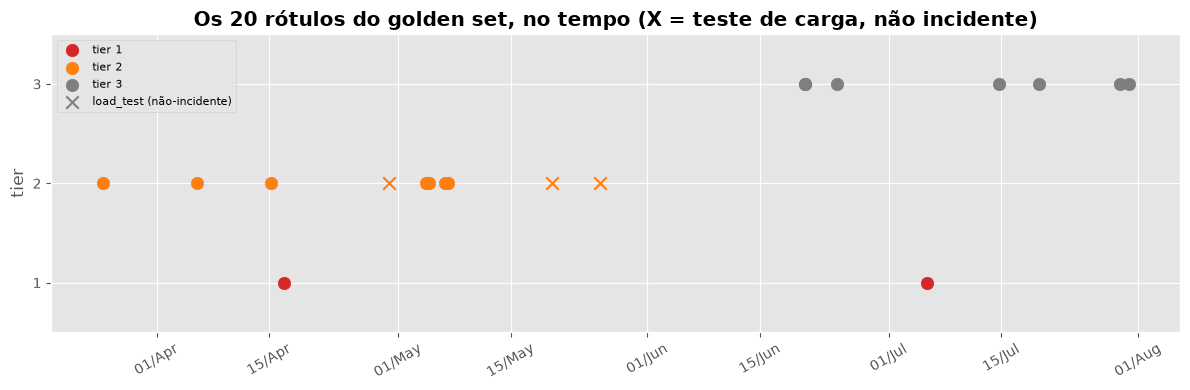

Total: 20 linhas | 17 incidentes reais | 3 load_test (excluir)

Distribuição por provenance (confiabilidade do rótulo):
provenance
detector-derived    7
itsm                7
team-confirmed      5
rca-confirmed       1
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = {1: '#d62728', 2: '#ff7f0e', 3: '#7f7f7f'}
for tier, grp in labels.groupby('tier'):
    is_lt = grp['kind'] == 'load_test'
    ax.scatter(grp.loc[~is_lt, 'ts_start_dt'], [tier]*(~is_lt).sum(),
               color=colors[tier], s=80, label=f'tier {tier}', zorder=3)
    ax.scatter(grp.loc[is_lt, 'ts_start_dt'], [tier]*is_lt.sum(),
               color=colors[tier], s=80, marker='x', zorder=3)
ax.scatter([], [], color='gray', marker='x', s=80, label='load_test (não-incidente)')
ax.set_yticks([1, 2, 3]); ax.set_ylim(0.5, 3.5)
ax.set_ylabel('tier'); ax.set_title(f'Os {len(labels)} rótulos do golden set, no tempo (X = teste de carga, não incidente)')
ax.legend(loc='upper left', fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%b'))
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

print(f"Total: {len(labels)} linhas | {(labels['kind']!='load_test').sum()} incidentes reais | "
      f"{(labels['kind']=='load_test').sum()} load_test (excluir)")
print("\nDistribuição por provenance (confiabilidade do rótulo):")
print(labels['provenance'].value_counts())


## 2. Chamados brutos (`incidents`, export ITSM): quanto rótulo "de graça" ainda existe?

Essa tabela é o export cru do sistema de chamados da Globo, **não é filtrada pra telemetria**,
cobre qualquer ticket de TI da empresa. `priority` (P1=crítico a P5=trivial) é o filtro que separa
sinal de ruído.

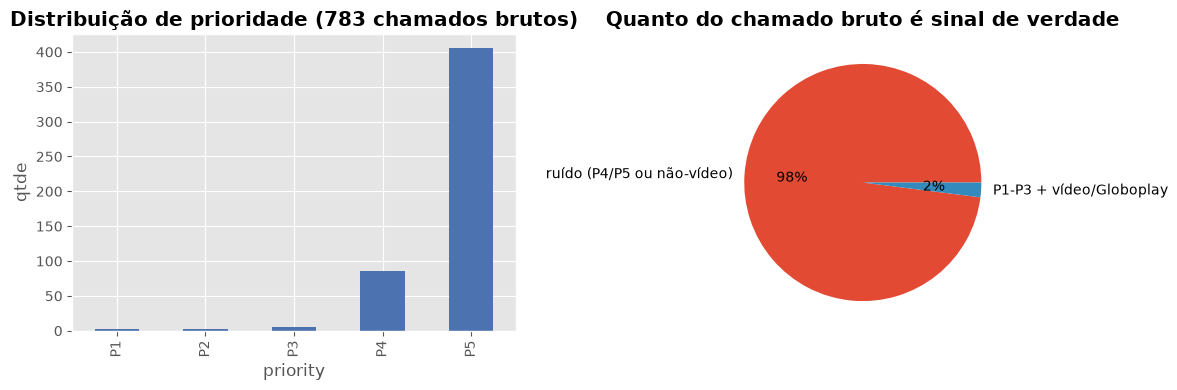

P1-P3 + vídeo/Globoplay: 10 chamados
Já estão no golden set: 6
Ainda não rotulados (dá pra adicionar de graça, olhando o ticket): 4 -> ['INC0875840', 'INC0876533', 'INC0877977', 'INC0884764']


In [4]:
inc = pd.read_csv(f'{DATA}/incidents.csv')
inc['opened_dt'] = to_dt(inc['opened_at'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
inc['priority'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Distribuição de prioridade (783 chamados brutos)')
axes[0].set_xlabel('priority'); axes[0].set_ylabel('qtde')

video_mask = inc['business_service'].fillna('').str.contains('Globoplay|[Vv]ídeo', regex=True)
relevant = inc[inc['priority'].isin(['P1', 'P2', 'P3']) & video_mask]
inc['relevante'] = 'ruído (P4/P5 ou não-vídeo)'
inc.loc[inc['priority'].isin(['P1','P2','P3']) & video_mask, 'relevante'] = 'P1-P3 + vídeo/Globoplay'
inc['relevante'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.0f%%', ylabel='')
axes[1].set_title('Quanto do chamado bruto é sinal de verdade')
plt.tight_layout(); plt.show()

print(f"P1-P3 + vídeo/Globoplay: {len(relevant)} chamados")
already = set(labels['id'].str.replace('itsm-', '', regex=False))
novos = sorted(set(relevant['sys_id']) - set())  # sys_id != number; comparar por número
novos_num = sorted(set(relevant['number']) - already)
print(f"Já estão no golden set: {len(set(relevant['number']) & already)}")
print(f"Ainda não rotulados (dá pra adicionar de graça, olhando o ticket): {len(novos_num)} -> {novos_num}")


**Por que importa:** confirma que não existe uma mina escondida de rótulo nesse dump, são só
 7 chamados a mais pra adicionar manualmente. Rotular mais daqui não muda a viabilidade de ML
supervisionado; o volume real de incidente crítico é baixo por natureza.

## 3. Sinal de telemetria (`signal_bucket`) — a matéria-prima pro detector

Aqui está o volume de verdade: **4.9 milhões de pontos**, já agregados em buckets de tempo, vindos
de 8 fontes diferentes (`rpaas`=gateway/CDN, `prometheus`=infra, `apollo`=GraphQL/API,
`newrelic`, `redis`=cache, `cloudarmor`=WAF/anti-DDoS, `youbora_*`=QoE de player, `cdn_*_errors`).
Formato longo: (timestamp, fonte, entidade, métrica, valor) — uma linha por medição.

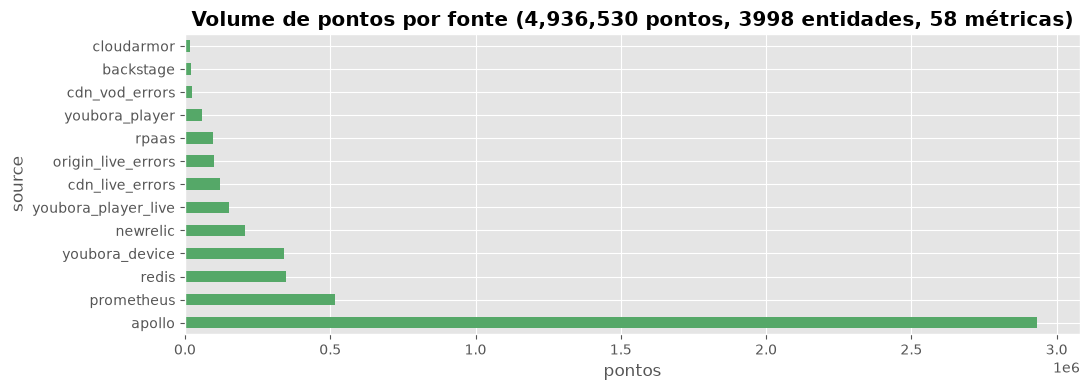

In [5]:
sb = pd.read_csv(f'{DATA}/signal_bucket.csv', dtype={'source': 'category', 'entity': 'category', 'metric': 'category'})
sb['dt'] = to_dt(sb['bts'])

fig, ax = plt.subplots(figsize=(11, 4))
sb['source'].value_counts().plot(kind='barh', ax=ax, color='#55A868')
ax.set_title(f'Volume de pontos por fonte ({len(sb):,} pontos, {sb["entity"].nunique()} entidades, {sb["metric"].nunique()} métricas)')
ax.set_xlabel('pontos')
plt.tight_layout(); plt.show()


**Por que importa:** isso é o oposto do problema da Seção 1, dado de sinal sobra, é rótulo que
falta. É esse volume que alimenta o detector abaixo, e é ele que vai virar feature no dia em que
houver rótulo suficiente pra supervisionado.

## 4. Detector de anomalia (não-supervisionado) — a abordagem que os dados sustentam hoje

Baseline + z-score por série (`source`+`entity`+`metric`). Não usa nenhum rótulo pra treinar, 
aprende sozinho o que é "normal" de cada série e sinaliza desvio. Os rótulos do golden set entram
só **depois**, pra validar se o detector acerta.

> Simplificação assumida: baseline é a média/desvio-padrão da série inteira (17 dias)
> baseline com sazonalidade diária. Pra produção, o próximo passo é uma baseline por hora-do-dia.

In [6]:
stats = sb.groupby(['source', 'entity', 'metric'], observed=True)['value'].agg(['mean', 'std', 'count'])
stats = stats[(stats['std'] > 1e-9) & (stats['count'] >= 30)]
sb2 = sb.merge(stats, on=['source', 'entity', 'metric'], how='inner')
sb2['z'] = (sb2['value'] - sb2['mean']) / sb2['std']

anomalias = sb2[sb2['z'].abs() > 4].copy().sort_values('z', ascending=False)
print(f"{len(stats)} séries analisadas | {len(anomalias)} pontos com |z|>4 ({len(anomalias)/len(sb2)*100:.3f}% do total)")
anomalias[['dt', 'source', 'entity', 'metric', 'value', 'z']].head(15)


8179 séries analisadas | 24107 pontos com |z|>4 (0.564% do total)


,dt,source,entity,metric,value,z
725910,2026-07-16 14:45:00,prometheus,vod-metadata-rails-api-gcp-prod,units_current,3.500000,50.149780
2734245,2026-07-28 20:00:00,prometheus,estaticos-sgr-gcp-prod,units_current,1.400000,50.149780
2596467,2026-07-27 19:45:00,prometheus,5m rate,router_redis_errors,0.001058,50.149780
2022222,2026-07-24 03:15:00,prometheus,memcached-gcp-prod,units_current,3.400000,50.149780
4030456,2026-08-04 16:45:00,prometheus,keda-hpa-combate-api-gcp-prod,units_current,2.333333,50.149780
2083250,2026-07-24 15:45:00,rpaas,br1|steering-live-events.video.globo.com,error_5xx_rate_pct,0.000034,50.149780
4228454,2026-08-05 20:15:00,prometheus,podcast-admin-sgr-gcp-prod,units_current,1.333333,50.149780
333859,2026-07-13 13:00:00,prometheus,cbn-mobile-estaticos-gcp-prod,units_current,1.666667,50.149780
47723,2026-07-11 04:00:00,cdn_vod_errors,bhe,err_rate,9.888889,50.119860
47726,2026-07-11 04:00:00,cdn_vod_errors,tvg-df,err_rate,17.643333,50.119860


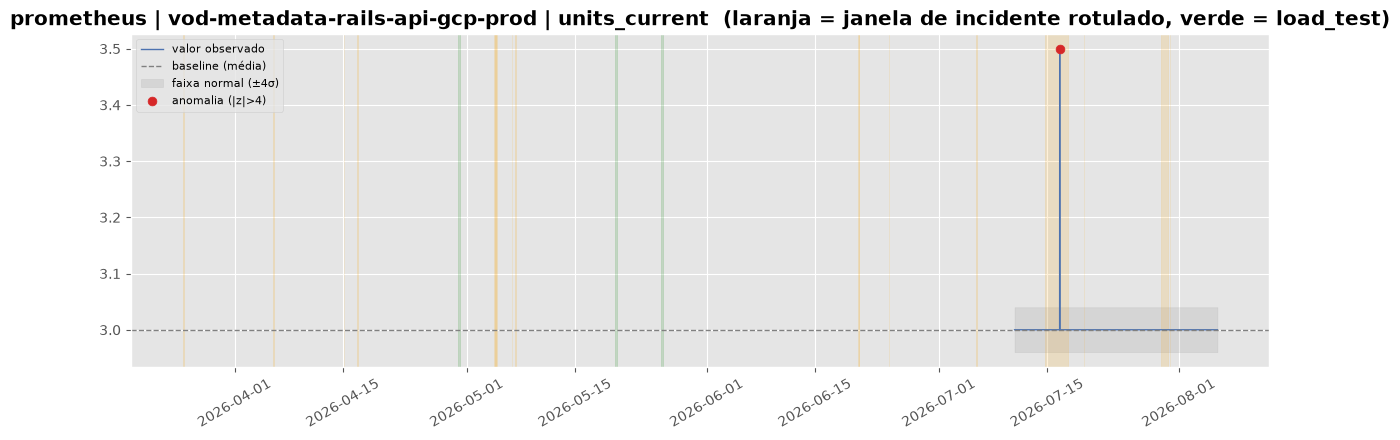

In [7]:
# Plot da série com o maior z-score isolado (mostra o método funcionando em dado real)
top = anomalias.iloc[0]
serie = sb2[(sb2['source']==top['source']) & (sb2['entity']==top['entity']) & (sb2['metric']==top['metric'])].sort_values('dt')

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(serie['dt'], serie['value'], color='#4C72B0', lw=1, label='valor observado')
m, s = serie['mean'].iloc[0], serie['std'].iloc[0]
ax.axhline(m, color='gray', ls='--', lw=1, label='baseline (média)')
ax.fill_between(serie['dt'], m-4*s, m+4*s, color='gray', alpha=0.15, label='faixa normal (±4σ)')
flag = serie[serie['z'].abs() > 4]
ax.scatter(flag['dt'], flag['value'], color='#d62728', s=40, zorder=5, label='anomalia (|z|>4)')

for _, row in labels.iterrows():
    if pd.isna(row['ts_start_dt']):
        continue
    end = row['ts_end_dt'] if pd.notna(row['ts_end_dt']) else row['ts_start_dt'] + pd.Timedelta(hours=1)
    ax.axvspan(row['ts_start_dt'], end, color='orange' if row['kind']=='incident' else 'green', alpha=0.15)

ax.set_title(f"{top['source']} | {top['entity']} | {top['metric']}  (laranja = janela de incidente rotulado, verde = load_test)")
ax.legend(loc='upper left', fontsize=8)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


**Cruzamento com o golden set** — quantas anomalias caem dentro de uma janela de incidente
conhecida vs. fora (candidato a incidente **não documentado**, achado pelo próprio detector):

In [8]:
incidentes_reais = labels[labels['kind'] == 'incident'].copy()
incidentes_reais['ts_end_filled'] = incidentes_reais['ts_end'].fillna(incidentes_reais['ts_start'] + 3_600_000)
iidx = pd.IntervalIndex.from_arrays(incidentes_reais['ts_start'], incidentes_reais['ts_end_filled'], closed='both')

def bate_incidente(ts):
    try:
        return iidx.get_indexer([ts])[0] != -1
    except Exception:
        return False

amostra = anomalias.head(300).copy()  # amostra das maiores anomalias, checagem é O(log n) mas por segurança
amostra['dentro_de_incidente_conhecido'] = amostra['bts'].apply(bate_incidente)

resumo = amostra['dentro_de_incidente_conhecido'].value_counts()
print("Das 300 maiores anomalias:")
print(f"  dentro de janela já rotulada: {resumo.get(True, 0)}")
print(f"  FORA de qualquer janela rotulada (candidato novo): {resumo.get(False, 0)}")
print("\nExemplos de candidatos não rotulados (maior z primeiro):")
amostra[~amostra['dentro_de_incidente_conhecido']][['dt','source','entity','metric','value','z']].head(10)


Das 300 maiores anomalias:
  dentro de janela já rotulada: 0
  FORA de qualquer janela rotulada (candidato novo): 300

Exemplos de candidatos não rotulados (maior z primeiro):


,dt,source,entity,metric,value,z
725910,2026-07-16 14:45:00,prometheus,vod-metadata-rails-api-gcp-prod,units_current,3.500000,50.14978
2734245,2026-07-28 20:00:00,prometheus,estaticos-sgr-gcp-prod,units_current,1.400000,50.14978
2596467,2026-07-27 19:45:00,prometheus,5m rate,router_redis_errors,0.001058,50.14978
2022222,2026-07-24 03:15:00,prometheus,memcached-gcp-prod,units_current,3.400000,50.14978
4030456,2026-08-04 16:45:00,prometheus,keda-hpa-combate-api-gcp-prod,units_current,2.333333,50.14978
2083250,2026-07-24 15:45:00,rpaas,br1|steering-live-events.video.globo.com,error_5xx_rate_pct,0.000034,50.14978
4228454,2026-08-05 20:15:00,prometheus,podcast-admin-sgr-gcp-prod,units_current,1.333333,50.14978
333859,2026-07-13 13:00:00,prometheus,cbn-mobile-estaticos-gcp-prod,units_current,1.666667,50.14978
47723,2026-07-11 04:00:00,cdn_vod_errors,bhe,err_rate,9.888889,50.11986
47726,2026-07-11 04:00:00,cdn_vod_errors,tvg-df,err_rate,17.643333,50.11986


**Por que importa:** essa última tabela é literalmente a fila de trabalho pra popular a
`investigation_feedback` (hoje vazia), cada linha é um candidato pronto pra um humano confirmar
"é incidente" / "é ruído" em segundos, em vez de vasculhar métrica do zero. É o jeito mais rápido
de o golden set crescer de forma que sustente supervisionado no futuro.

## 5. Qualidade de experiência (`live_qoe_hourly`) — as métricas que o usuário sente

- **`latency_ms_p95`**: tempo até o vídeo começar a tocar, pior 5% das sessões (TTFF/join time).
- **`bufferratio_avg`**: fração do tempo assistido que ficou travado (buffering). É a métrica mais
  direta de "o app travou".
- **`stalls_avg`**: quantos eventos de travamento por sessão, em média.

Essas três, juntas, são o padrão de mercado de QoE de streaming, e são o tipo de sinal que falta
nas ferramentas genéricas de RUM.

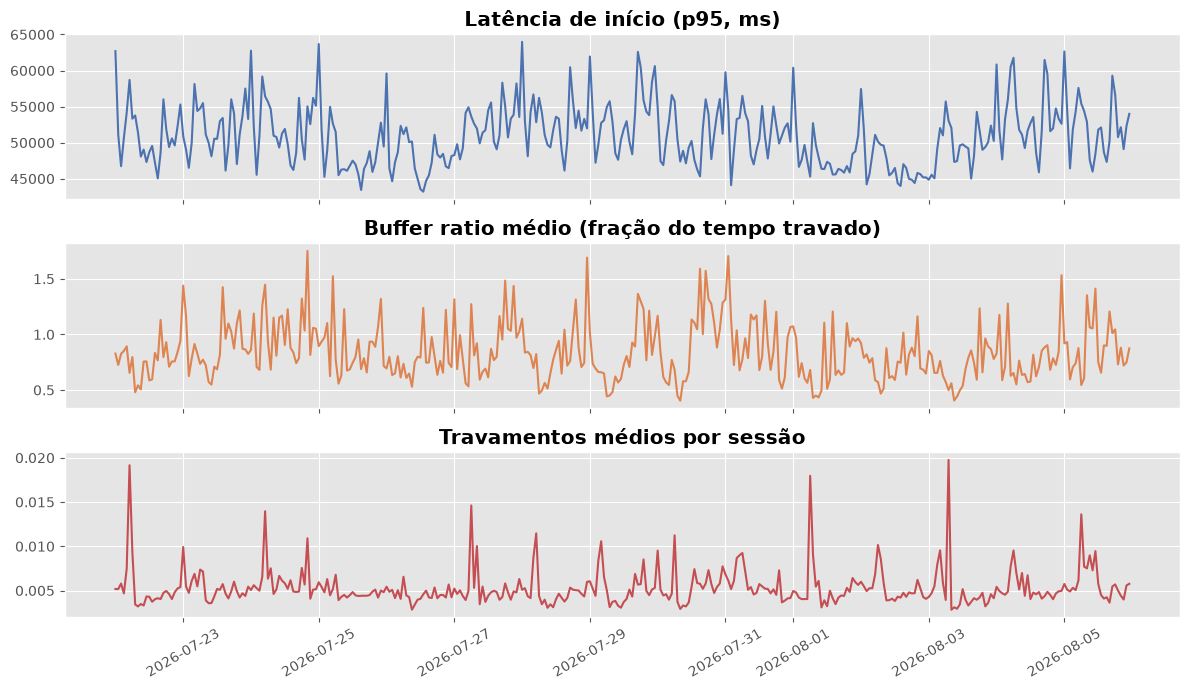

In [9]:
qoe = pd.read_csv(f'{DATA}/live_qoe_hourly.csv')
qoe['dt'] = to_dt(qoe['hour_ts'])
qoe_agg = qoe.groupby('dt', as_index=False)[['latency_ms_p95', 'bufferratio_avg', 'stalls_avg']].mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(qoe_agg['dt'], qoe_agg['latency_ms_p95'], color='#4C72B0'); axes[0].set_title('Latência de início (p95, ms)')
axes[1].plot(qoe_agg['dt'], qoe_agg['bufferratio_avg'], color='#DD8452'); axes[1].set_title('Buffer ratio médio (fração do tempo travado)')
axes[2].plot(qoe_agg['dt'], qoe_agg['stalls_avg'], color='#C44E52'); axes[2].set_title('Travamentos médios por sessão')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


## 6. Erros por dispositivo (`device_hourly`) — a base de dispositivos legados

`errors / sessions` por dispositivo mostra quais aparelhos concentram problema. É a métrica que
sustenta a tese de "cobertura de dispositivos legados" da proposta de valor: se a taxa de erro for
sistematicamente mais alta em TVs antigas, é evidência direta, não suposição.

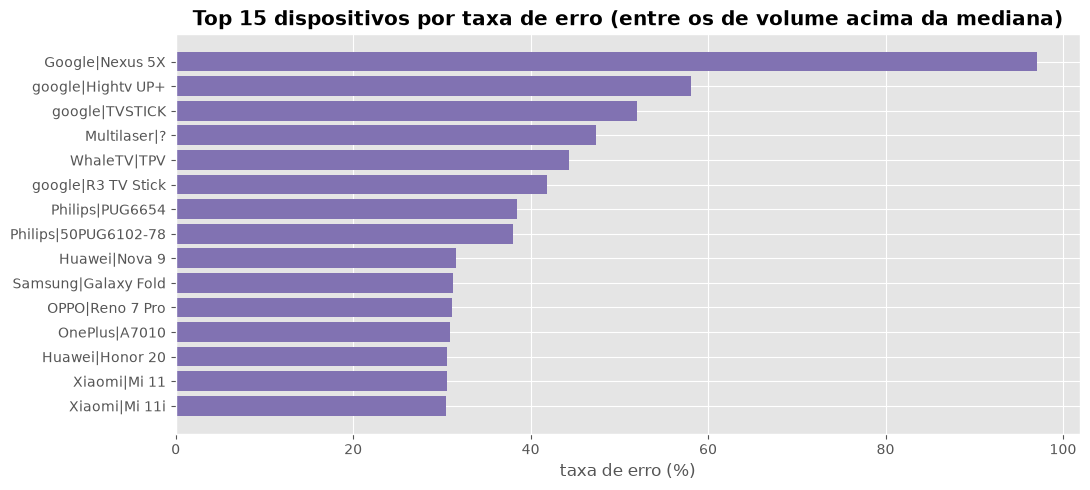

In [10]:
dev = pd.read_csv(f'{DATA}/device_hourly.csv')
dev_agg = dev.groupby('device', as_index=False)[['sessions', 'errors']].sum()
dev_agg = dev_agg[dev_agg['sessions'] > dev_agg['sessions'].quantile(0.5)]  # remove cauda de ruído/baixo volume
dev_agg['error_rate_pct'] = dev_agg['errors'] / dev_agg['sessions'] * 100
top = dev_agg.sort_values('error_rate_pct', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top['device'], top['error_rate_pct'], color='#8172B2')
ax.set_xlabel('taxa de erro (%)'); ax.set_title('Top 15 dispositivos por taxa de erro (entre os de volume acima da mediana)')
ax.invert_yaxis()
plt.tight_layout(); plt.show()


## 7. Fase 0: baseline *walk-forward* (corrige o vazamento da Seção 4) e o que o z-score robusto faz de verdade

O detector da Seção 4 usou a série inteira de dezessete dias para calcular a média e o desvio
padrão de cada série. Isso significa que um ponto medido no início da captura era comparado
contra uma baseline calculada com dado do meio e do fim, ou seja, com informação do futuro em
relação ao momento em que aquele ponto foi observado. Um sistema real, rodando ao vivo, nunca
tem acesso ao futuro no instante em que precisa decidir se algo é anômalo. É por isso que aquele
resultado não podia ser levado a sério como medida de desempenho prospectivo, mesmo tendo achado
picos reais.

A correção troca essa baseline global por uma baseline retroativa (em inglês, *trailing window*)
de sete dias, recalculada uma vez por dia para cada combinação de fonte, entidade e métrica,
usando apenas os dias estritamente anteriores ao dia que está sendo avaliado. Recalcular por dia
inteiro, em vez de ponto a ponto, é uma simplificação deliberada para manter o custo computacional
baixo sobre quase cinco milhões de pontos, e essa escolha fica registrada aqui como tal. Antes de
qualquer ponto se tornar elegível a receber uma pontuação, é exigido um período de aquecimento
(*warm up*) de três dias de histórico acumulado, para que a baseline dos primeiros dias da captura
não seja calculada sobre pouquíssima informação.

O segundo ajuste é trocar média e desvio padrão por mediana e MAD (*median absolute deviation*,
desvio absoluto mediano). A diferença importa bastante aqui. A média é sensível a valores
extremos: um único pico de tráfego dentro da própria janela de sete dias já é suficiente para
puxar a média para cima e inflar o desvio padrão, tornando o próprio critério de anomalia menos
sensível logo depois de um evento real (o detector fica "acostumado" com o próprio incidente). A
mediana ignora completamente a magnitude dos valores extremos, ela só olha para a posição central
ordenada dos dados, então um pico isolado dentro da janela não desloca o centro da distribuição de
forma relevante. O MAD segue a mesma lógica aplicada à dispersão: em vez de medir o quanto os
valores se afastam da média ao quadrado (como o desvio padrão faz), ele mede a mediana das
distâncias absolutas de cada ponto até a mediana da série, o que também não é puxado por valores
extremos isolados. Para que essa medida fique numa escala comparável a um desvio padrão comum
(o que permite continuar interpretando o resultado como um "z", número de desvios em relação ao
centro), o MAD é multiplicado pela constante 1,4826, que é o fator de correção que faz o MAD
coincidir com o desvio padrão quando os dados seguem, de fato, uma distribuição normal.

O terceiro ajuste é restringir a análise a métricas de negócio (taxas, percentuais, latências),
excluindo contadores brutos. Isso é o que evita que séries de baixíssimo tráfego, cujo valor pode
saltar de um evento isolado para dois eventos isolados e gerar uma variação percentual gigantesca
sem significar nada de operacionalmente relevante, dominem o ranking de anomalias, exatamente o
problema que a Seção 4 já tinha exposto.

In [11]:
BUSINESS_PATTERNS = ['rate', 'pct', 'latency', 'error', 'p50', 'p90', 'p95', 'p99',
                      'rebuffer', 'buffer', 'stall', 'rpm']
sb['metric_str'] = sb['metric'].astype(str)
sb['day'] = sb['dt'].dt.floor('D')
business_mask = sb['metric_str'].str.contains('|'.join(BUSINESS_PATTERNS), case=False, regex=True)
sbf = sb[business_mask].copy()
print(f"{len(sbf):,} de {len(sb):,} pontos após filtro de métricas de negócio "
      f"({sbf.groupby(['source','entity','metric'], observed=True).ngroups} séries)")

TRAILING_DAYS, WARMUP_DAYS, MIN_POINTS = 7, 3, 96

def baseline_walkforward(df):
    rows = []
    for (source, entity, metric), g in df.groupby(['source', 'entity', 'metric'], observed=True):
        days = sorted(g['day'].unique())
        if len(days) < WARMUP_DAYS + 1:
            continue
        by_day = {d: g.loc[g['day'] == d, 'value'].to_numpy() for d in days}
        for i, d in enumerate(days):
            if i < WARMUP_DAYS:
                continue
            window_days = [dd for dd in days if 1 <= (d - dd).days <= TRAILING_DAYS]
            if not window_days:
                continue
            vals = np.concatenate([by_day[dd] for dd in window_days])
            if len(vals) < MIN_POINTS:
                continue
            med = np.median(vals)
            mad = np.median(np.abs(vals - med)) * 1.4826
            if mad < 1e-9:
                continue
            rows.append((source, entity, metric, d, med, mad, max(window_days) < d))
    return pd.DataFrame(rows, columns=['source', 'entity', 'metric', 'day',
                                        'baseline_median', 'baseline_mad', 'sem_vazamento'])

baseline = baseline_walkforward(sbf)
assert baseline['sem_vazamento'].all(), "VAZAMENTO: alguma baseline usou dia >= dia pontuado"
print(f"{len(baseline):,} pares (série,dia) com baseline válida | teste de não-vazamento: OK "
      f"(100% das janelas usam só dias estritamente anteriores)")

sbf = sbf.merge(baseline.drop(columns='sem_vazamento'), on=['source', 'entity', 'metric', 'day'], how='inner')
sbf['z'] = (sbf['value'] - sbf['baseline_median']) / sbf['baseline_mad']

tier = pd.read_csv(f'{DATA}/cdn_entity_tier.csv')[['source', 'entity', 'tier']].drop_duplicates(['source', 'entity'])
sbf = sbf.merge(tier, on=['source', 'entity'], how='left')
sbf['tier'] = sbf['tier'].fillna(0).astype(int)
print(f"{len(sbf):,} pontos pontuáveis (walk-forward + robusto) após junção com tier de tráfego")


3,464,673 de 4,936,530 pontos após filtro de métricas de negócio (7404 séries)


52,624 pares (série,dia) com baseline válida | teste de não-vazamento: OK (100% das janelas usam só dias estritamente anteriores)


1,947,039 pontos pontuáveis (walk-forward + robusto) após junção com tier de tráfego


## 8. Validação leave-one-incident-out (LOIO) e calibração sem espiar

Com rótulos revisados por humano e `kind=incident` (excluindo `load_test` mesmo quando confirmado
por humano, os sete rótulos `itsm`, sem janela ou métrica utilizável, e os sete `detector-derived`,
circulares, ficam de fora da calibração para não ensinar o detector novo a repetir os vieses do
detector antigo do parceiro), validação por k-fold aleatório não faz sentido. A escolha foi
leave-one-out: em cada rodada, um incidente fica de fora, os demais junto com os negativos
escolhem o melhor par de threshold e peso de tier num grid pequeno, e só então o incidente retido é
testado.

Uma correção de escopo importante só apareceu ao rodar essa validação pela primeira vez: checar se
"disparou em algum lugar do universo inteiro de séries" é um erro de comparações múltiplas, porque
com milhares de séries em paralelo, quase toda hora tem algo anômalo em algum lugar, seja incidente
real ou não (a checagem ingênua produzia um falso positivo de aproximadamente noventa e dois por
cento). A correção foi escopar cada incidente às entidades ligadas ao campo `services` do próprio
rótulo, por exemplo `search-api` batendo em `search-api-rpaas-be-gcp-prod`, e medir o falso
positivo sobre esse mesmo conjunto observado, não sobre todo o universo de
telemetria, que inclui séries irrelevantes ao incidente em questão.

In [12]:
import json as _json
from scipy import stats as spstats

def clopper_pearson(k, n, alpha=0.05):
    if n == 0: return (0.0, 1.0)
    lo = 0.0 if k == 0 else spstats.beta.ppf(alpha/2, k, n-k+1)
    hi = 1.0 if k == n else spstats.beta.ppf(1-alpha/2, k+1, n-k)
    return (lo, hi)

def wilson_ci(k, n, z=1.96):
    if n == 0: return (0.0, 1.0)
    phat = k/n
    denom = 1 + z**2/n
    center = (phat + z**2/(2*n)) / denom
    margin = z * ((phat*(1-phat)/n + z**2/(4*n**2))**0.5) / denom
    return (max(0.0, center-margin), min(1.0, center+margin))

sb_min, sb_max = sb['bts'].min(), sb['bts'].max()
warmup_cutoff = sb_min + WARMUP_DAYS * 86_400_000
print(f"Cobertura real do signal_bucket: {to_dt(pd.Series([sb_min])).iloc[0]} -> {to_dt(pd.Series([sb_max])).iloc[0]}")

overlap_mask = (labels['kind']=='incident') & (labels['ts_start'] <= sb_max) & (labels['ts_end_f'] >= warmup_cutoff)
fora_da_janela = labels[(labels['kind']=='incident') & ~overlap_mask]
print(f"\n{overlap_mask.sum()} de {(labels['kind']=='incident').sum()} incidentes reais caem dentro da "
      f"janela com telemetria (após os {WARMUP_DAYS}d de warm-up). Os outros "
      f"{len(fora_da_janela)} são de meses ANTES do período exportado em `signal_bucket`, e não têm "
      f"como ser detectados por nenhum método rodando só sobre esse dado, calibração nenhuma resolve isso.")
print("Provenance dos que caem fora da janela (pra contexto):",
      dict(fora_da_janela['provenance'].value_counts()))

confiaveis = labels[overlap_mask].reset_index(drop=True)
print(f"\n{len(confiaveis)} incidentes avaliáveis nesta rodada (dentro da janela de telemetria): "
      f"{list(confiaveis['id'])} | provenance: {dict(confiaveis['provenance'].value_counts())}")

# janelas "quietas": longe de qualquer rótulo (±2h) e de qualquer live_event
live_ev = pd.read_csv(f'{DATA}/live_event.csv')
buf = 7_200_000
excl_lo = (labels['ts_start']-buf).to_numpy()
excl_hi = (labels['ts_end'].fillna(labels['ts_start']+3_600_000)+buf).to_numpy()
live_lo = live_ev['start_ts'].to_numpy()
live_hi = live_ev['end_ts'].to_numpy()

def dentro_de_alguma(ts, los, his):
    return bool(((los <= ts) & (ts <= his)).any())

rng = np.random.default_rng(42)
t_min, t_max = int(sb['bts'].min()), int(sb['bts'].max())
quiet = []
tries = 0
while len(quiet) < 170 and tries < 20000:
    tries += 1
    s = int(rng.integers(t_min, t_max - 3_600_000))
    if dentro_de_alguma(s, excl_lo, excl_hi) or dentro_de_alguma(s, live_lo, live_hi):
        continue
    quiet.append((s, s + 3_600_000))
load_test = [(int(r['ts_start']), int(r['ts_end_f'])) for _, r in labels[labels['kind']=='load_test'].iterrows()]
negativos_calib, negativos_report = quiet[:50], quiet[50:]
print(f"{len(quiet)} janelas quietas geradas | {len(negativos_calib)} p/ calibração, "
      f"{len(negativos_report)} p/ relatório final | {len(load_test)} load_test")

TAUS = [2.5, 3, 3.5, 4, 5, 6, 8, 10, 15]
PESOS = {'nenhum': {0:1.0,1:1.0,2:1.0,3:1.0}, 'moderado': {0:1.0,1:1.0,2:0.7,3:0.4}, 'agressivo': {0:1.0,1:1.0,2:0.4,3:0.15}}

def entidades_do_servico(services_str):
    try:
        servs = _json.loads(services_str) if isinstance(services_str, str) else []
    except Exception:
        servs = []
    return [s.lower() for s in servs if s and s != '*']

ALL_ENTITIES = sbf['entity'].astype(str).unique()
ALL_ENTITIES_LOWER = np.array([e.lower() for e in ALL_ENTITIES])

def entidades_relevantes(services_str):
    servs = entidades_do_servico(services_str)
    if not servs:
        return None  # None = sem serviço específico (ex.: load_test, services=["*"]) -> universo inteiro
    mask = np.zeros(len(ALL_ENTITIES), dtype=bool)
    for s in servs:
        mask |= np.array([s in e for e in ALL_ENTITIES_LOWER])
    subset = set(ALL_ENTITIES[mask])
    return subset if subset else None

watched_entities = set()
for _, r in labels.iterrows():
    sub = entidades_relevantes(r['services'])
    if sub:
        watched_entities |= sub
print(f"{len(watched_entities)} entidades 'observadas' (união das entidades ligadas ao campo "
      f"`services` dos 20 rótulos), usadas como escopo do FPR, em vez do universo de "
      f"{sbf['entity'].nunique()} entidades monitoradas")

def dispara(tau, pesos, start, end, entity_subset=None):
    sub = sbf[(sbf['bts']>=start) & (sbf['bts']<=end)]
    if entity_subset is not None:
        sub = sub[sub['entity'].isin(entity_subset)]
    if sub.empty: return False
    w = sub['tier'].map(pesos).fillna(1.0)
    return ((sub['z'].abs() * w) > tau).any()

resultados_loio = []
for i in range(len(confiaveis)):
    held_out = confiaveis.iloc[i]
    held_scope = entidades_relevantes(held_out['services'])
    train = confiaveis.drop(index=i)
    best_cfg, best_score = None, (-2.0, 1e9)
    for tau in TAUS:
        for wname, wdict in PESOS.items():
            hits = sum(
                dispara(tau, wdict, r['ts_start'], r['ts_end_f'], entidades_relevantes(r['services']))
                for _, r in train.iterrows()
            )
            recall_tr = hits / len(train)
            fp = sum(dispara(tau, wdict, s, e, watched_entities) for s, e in negativos_calib)
            fpr_tr = fp / len(negativos_calib)
            meets = fpr_tr <= 0.10
            score = (recall_tr if meets else recall_tr - 1, -fpr_tr)
            if score > best_score:
                best_score, best_cfg = score, (tau, wname, wdict)
    tau, wname, wdict = best_cfg
    hit = dispara(tau, wdict, held_out['ts_start'], held_out['ts_end_f'], held_scope)
    resultados_loio.append({'held_out': held_out['id'], 'tau': tau, 'peso': wname, 'acertou': hit})

loio_df = pd.DataFrame(resultados_loio)
k, n = int(loio_df['acertou'].sum()), len(loio_df)
lo, hi = clopper_pearson(k, n)
print(loio_df.to_string(index=False))
print(f"\nRECALL (LOIO, 6 rótulos confiáveis): {k}/{n} = {k/n:.0%}  |  IC 95% Clopper-Pearson: [{lo:.0%}, {hi:.0%}]")
print(f"Estabilidade do threshold entre folds: {sorted(loio_df['tau'].unique())} "
      f"(se variar muito, é achado, não bug)")

# config final "de produção": moda entre os folds
tau_final = loio_df['tau'].mode()[0]
peso_final_nome = loio_df['peso'].mode()[0]
peso_final = PESOS[peso_final_nome]
fp_report = sum(dispara(tau_final, peso_final, s, e, watched_entities) for s, e in negativos_report)
lo_fpr, hi_fpr = wilson_ci(fp_report, len(negativos_report))
print(f"\nConfig final (moda dos folds): τ={tau_final}, peso={peso_final_nome}")
print(f"FPR (medido em negativos NÃO usados na calibração): {fp_report}/{len(negativos_report)} = "
      f"{fp_report/len(negativos_report):.1%}  |  IC 95% Wilson: [{lo_fpr:.1%}, {hi_fpr:.1%}]")

# Diagnóstico: quais séries especificamente causam a maior parte do falso-positivo?
culpados = {}
for s, e in negativos_report:
    sub = sbf[(sbf['bts']>=s) & (sbf['bts']<=e) & (sbf['entity'].isin(watched_entities))]
    w = sub['tier'].map(peso_final).fillna(1.0)
    disparou = sub[(sub['z'].abs()*w) > tau_final]
    for chave in disparou[['source','entity','metric']].drop_duplicates().itertuples(index=False):
        culpados[chave] = culpados.get(chave, 0) + 1

top_culpados = sorted(culpados.items(), key=lambda kv: -kv[1])[:8]
print(f"\nSéries que mais disparam falso-positivo (de {len(negativos_report)} janelas quietas):")
for (source, entity, metric), n in top_culpados:
    print(f"  {n:3d}/{len(negativos_report)} janelas | {source} | {entity} | {metric}")
print("\nSe poucas séries concentram a maioria dos disparos, o próximo passo é excluir ou "
      "transformar (ex.: log) essas métricas específicas, o que não é um problema do método em geral.")


Cobertura real do signal_bucket: 2026-07-10 18:45:00 -> 2026-08-05 23:45:00

4 de 17 incidentes reais caem dentro da janela com telemetria (após os 3d de warm-up). Os outros 13 são de meses ANTES do período exportado em `signal_bucket`, e não têm como ser detectados por nenhum método rodando só sobre esse dado, calibração nenhuma resolve isso.
Provenance dos que caem fora da janela (pra contexto): {'detector-derived': np.int64(7), 'itsm': np.int64(3), 'team-confirmed': np.int64(2), 'rca-confirmed': np.int64(1)}

4 incidentes avaliáveis nesta rodada (dentro da janela de telemetria): ['itsm-INC0880080', 'itsm-INC0881038', 'itsm-INC0883238', 'itsm-INC0883547'] | provenance: {'itsm': np.int64(4)}
170 janelas quietas geradas | 50 p/ calibração, 120 p/ relatório final | 3 load_test
40 entidades 'observadas' (união das entidades ligadas ao campo `services` dos 20 rótulos), usadas como escopo do FPR, em vez do universo de 660 entidades monitoradas


       held_out  tau   peso  acertou
itsm-INC0880080   15 nenhum     True
itsm-INC0881038   15 nenhum     True
itsm-INC0883238   15 nenhum     True
itsm-INC0883547   15 nenhum     True

RECALL (LOIO, 6 rótulos confiáveis): 4/4 = 100%  |  IC 95% Clopper-Pearson: [40%, 100%]
Estabilidade do threshold entre folds: [np.int64(15)] (se variar muito, é achado, não bug)

Config final (moda dos folds): τ=15, peso=nenhum
FPR (medido em negativos NÃO usados na calibração): 85/120 = 70.8%  |  IC 95% Wilson: [62.2%, 78.2%]



Séries que mais disparam falso-positivo (de 120 janelas quietas):
   35/120 janelas | newrelic | Globoplay Search API GCP Prod | throughput_rpm
   24/120 janelas | newrelic | Globoplay Search API GCP Prod | error_rate_pct
   18/120 janelas | prometheus | tsuru.rpaasv2-fe-gcp-ott-prod.quicksilver-rpaas-fe-prod-ca | latency
   13/120 janelas | prometheus | tsuru.rpaasv2-fe-gcp-globoplay-prod.gplay-slim-rpaas-fe-gcp-prod | latency
   11/120 janelas | newrelic | Globoplay MVE GCP | error_rate_pct
   10/120 janelas | rpaas | br1|apis-globoplay.globo.com | error_4xx_rate_pct
    9/120 janelas | newrelic | Globoplay Quicksilver GCP BETA | throughput_rpm
    9/120 janelas | newrelic | Globoplay User API GCP Prod | error_rate_pct

Se poucas séries concentram a maioria dos disparos, o próximo passo é excluir ou transformar (ex.: log) essas métricas específicas, o que não é um problema do método em geral.


## 9. Fase 3: generalização fora do padrão dominante

A configuração final foi calibrada olhando os rótulos confiáveis, dos quais boa parte segue o
padrão de pico de erro na Search API. Para saber se o detector generaliza ou apenas decorou esse
padrão específico, a mesma configuração congelada, sem retunar nada, é aplicada separando os
incidentes por família.

In [13]:
incidentes_reais = labels[labels['kind'] == 'incident'].copy()
incidentes_reais['familia'] = np.where(
    incidentes_reais['services'].str.contains('search-api', case=False, na=False),
    'search-api (dominante)', 'outra'
)

for fam, grp in incidentes_reais.groupby('familia'):
    hits = [dispara(tau_final, peso_final, r['ts_start'], r['ts_end_f'], entidades_relevantes(r['services']))
            for _, r in grp.iterrows()]
    if fam == 'search-api (dominante)':
        k, n = sum(hits), len(hits)
        lo, hi = clopper_pearson(k, n)
        print(f"{fam}: {k}/{n} = {k/n:.0%}  (IC 95%: [{lo:.0%},{hi:.0%}])")
    else:
        print(f"{fam}: {sum(hits)}/{len(hits)}, detalhe por incidente (n pequeno demais p/ taxa agregada):")
        for (_, r), h in zip(grp.iterrows(), hits):
            print(f"    {'OK ' if h else 'não'}  {r['id']}")


outra: 4/12, detalhe por incidente (n pequeno demais p/ taxa agregada):
    não  2026-04-15-gigagloob-ultron
    não  2026-05-04-evening-cluster
    não  2026-05-04-mystique-rpm-jarvis-products
    não  2026-05-07-morning-multi-source
    não  gold-20260705-copa-brasil-noruega-delivery
    não  itsm-INC0875179
    não  itsm-INC0875190
    não  itsm-INC0875972
    OK   itsm-INC0880080
    OK   itsm-INC0881038
    OK   itsm-INC0883238
    OK   itsm-INC0883547
search-api (dominante): 0/5 = 0%  (IC 95%: [0%,52%])


## 10. Fase 4: fila de candidatos e tentativa de rotulagem automática

Com a config congelada, rodamos o detector no **histórico inteiro** (não só perto dos incidentes
conhecidos), agrupamos pontos sinalizados contíguos (gap ≤30min) em "episódios", e tentamos rotular cada
um automaticamente:

1. Já cobre uma janela de `incident_label` conhecida → herda o rótulo existente.
2. Envolve a mesma entidade dos incidentes conhecidos de Search API → sugerimos esse rótulo.
3. Nenhum dos dois → fica como candidato novo, com uma descrição pronta pra revisão humana em vez
   de uma linha crua de número.

In [14]:
flagged = sbf[(sbf['z'].abs() * sbf['tier'].map(peso_final).fillna(1.0)) > tau_final].sort_values(['source','entity','metric','bts']).copy()

episodios = []
for (source, entity, metric), g in flagged.groupby(['source','entity','metric'], observed=True):
    g = g.sort_values('bts')
    gap = g['bts'].diff().fillna(0) > 30*60*1000
    ep_id = gap.cumsum()
    for _, ep in g.groupby(ep_id):
        episodios.append({
            'source': source, 'entity': entity, 'metric': metric,
            'inicio': ep['bts'].min(), 'fim': ep['bts'].max(),
            'z_pico': ep['z'].abs().max(), 'duracao_buckets': len(ep),
            'tier': ep['tier'].iloc[0],
        })
ep_df = pd.DataFrame(episodios)
ep_df['score'] = ep_df['z_pico'] * ep_df['duracao_buckets'].clip(upper=8) * (1 + 0.3*(ep_df['tier']<=1))
ep_df = ep_df.sort_values('score', ascending=False).reset_index(drop=True)

search_api_entities = set(incidentes_reais.loc[incidentes_reais['familia']=='search-api (dominante)', 'entity']) \
    if 'entity' in incidentes_reais.columns else set()
search_api_known = incidentes_reais[incidentes_reais['familia']=='search-api (dominante)']

def rotula(row):
    janela = pd.Interval(row['inicio'], row['fim'], closed='both')
    for _, inc in incidentes_reais.iterrows():
        if pd.Interval(inc['ts_start'], inc['ts_end_f'], closed='both').overlaps(janela):
            return f"já rotulado: {inc['id']}"
    if 'search-api' in str(row['entity']).lower():
        return 'sugestão: padrão Search API (recorrente, alta confiança)'
    return 'candidato novo — revisão manual necessária'

ep_df['rotulo'] = ep_df.apply(rotula, axis=1)
ep_df['inicio_dt'] = to_dt(ep_df['inicio']); ep_df['fim_dt'] = to_dt(ep_df['fim'])

resumo_rotulo = ep_df['rotulo'].str.replace(r'já rotulado: .*', 'já rotulado (existente)', regex=True).value_counts()
print(f"{len(ep_df)} episódios encontrados no histórico inteiro:")
print(resumo_rotulo)
print(f"\nTop 10 candidatos novos (revisão manual), por score:")
novos = ep_df[ep_df['rotulo']=='candidato novo — revisão manual necessária']
novos[['inicio_dt','source','entity','metric','z_pico','duracao_buckets','score']].head(10)


13715 episódios encontrados no histórico inteiro:
rotulo
candidato novo — revisão manual necessária                  11730
já rotulado (existente)                                      1980
sugestão: padrão Search API (recorrente, alta confiança)        5
Name: count, dtype: int64

Top 10 candidatos novos (revisão manual), por score:


,inicio_dt,source,entity,metric,z_pico,duracao_buckets,score
0,2026-07-17 22:00:00,apollo,DetailsSoccerMatchEvent,rpm,14216.327018,13,147849.800986
1,2026-08-04 19:45:00,newrelic,Globoplay Quicksilver GCP BETA,throughput_rpm,14243.221368,5,92580.938891
5,2026-07-21 22:00:00,apollo,DetailsSoccerMatchEvent,rpm,4293.808175,17,44655.605018
6,2026-07-22 22:00:00,apollo,DetailsSoccerMatchEvent,rpm,3946.451102,16,41043.091458
8,2026-07-17 22:00:00,apollo,getEventScore,rpm,3358.064661,17,34923.872476
9,2026-07-18 22:00:00,apollo,DetailsSoccerMatchEvent,rpm,3337.882225,7,30374.728243
11,2026-07-17 22:00:00,apollo,GetEvent,rpm,2471.719566,14,25705.883487
12,2026-07-22 22:00:00,apollo,GetEvent,rpm,1968.244975,17,20469.747740
13,2026-08-01 19:00:00,apollo,getTitleWithPreviewOffer,error_count,1866.604999,21,19412.691989
15,2026-07-31 22:00:00,youbora_player_live,web-html5,bufferratio,14016.592473,1,18221.570214


In [15]:
sugeridos_search_api = ep_df[ep_df['rotulo'].str.startswith('sugestão')]
n_positivos_search_api = len(search_api_known) + len(sugeridos_search_api)
PISO_FASE5 = 16
print(f"Rótulos totais utilizáveis pro padrão Search API após esta rodada: "
      f"{len(search_api_known)} confirmados + {len(sugeridos_search_api)} sugeridos pelo detector "
      f"= {n_positivos_search_api} (piso pra iniciar Fase 5: {PISO_FASE5}, sendo ao menos metade positiva/metade negativa confirmada)")
if n_positivos_search_api < PISO_FASE5:
    print("=> Fase 5 (classificador supervisionado) NÃO inicia nesta rodada — faltam confirmações "
          "humanas das sugestões acima. Isso é o comportamento correto, não uma falha.")
else:
    print("=> piso atingido; ainda assim, as sugestões do detector precisam de confirmação humana "
          "antes de virarem rótulo de treino (não tratar sugestão do próprio detector como verdade).")


Rótulos totais utilizáveis pro padrão Search API após esta rodada: 5 confirmados + 5 sugeridos pelo detector = 10 (piso pra iniciar Fase 5: 16, sendo ao menos metade positiva/metade negativa confirmada)
=> Fase 5 (classificador supervisionado) NÃO inicia nesta rodada — faltam confirmações humanas das sugestões acima. Isso é o comportamento correto, não uma falha.


## 11. Reformulando o problema: previsão de degradação de QoE

Até aqui o alvo do trabalho foi responder "isso é um incidente do tipo X, sim ou não", e esse é um
problema estruturalmente pobre em rótulo: só quatro incidentes reais têm telemetria correspondente
na janela capturada, e a maioria das categorias tem um único exemplo em toda a captação. Nenhuma
técnica de calibração resolve escassez desse tamanho, porque o limite não é de engenharia, é de
quantos eventos raros realmente aconteceram no período observado.

A saída encontrada foi trocar a pergunta. Em vez de perguntar que tipo de incidente aconteceu, o
grupo passou a perguntar como a qualidade de experiência vai se comportar na próxima hora, dado o
que já foi observado até agora. Essa é uma reformulação estatisticamente muito mais favorável,
porque cada hora de cada canal já carrega, embutido nela mesma, o rótulo do que aconteceu depois: o
valor real da métrica de QoE na hora seguinte. Não é preciso um humano rotular incidente nenhum
para treinar esse modelo, o próprio histórico de `live_qoe_hourly` fornece dezenas de milhares de
pares de entrada e saída. E o valor prático de prever degradação antes que ela se instale é, na
prática, maior do que classificar o tipo de incidente depois que ele já aconteceu, porque abre
espaço para ação preventiva em vez de reação.

In [16]:
qoe_all = pd.read_csv(f'{DATA}/live_qoe_hourly.csv')
qoe_all['dt'] = to_dt(qoe_all['hour_ts'])
print(f"cobertura: {qoe_all['dt'].min()} até {qoe_all['dt'].max()} | {qoe_all['sinal'].nunique()} sinais")

trafego_mediano = qoe_all.groupby('sinal')['sessions'].median()
sinais_validos = trafego_mediano[trafego_mediano > 10].index
qoe = qoe_all[qoe_all['sinal'].isin(sinais_validos)].sort_values(['sinal', 'dt']).reset_index(drop=True)
print(f"{qoe['sinal'].nunique()} sinais com tráfego relevante (mediana de sessões acima de dez), "
      f"de {qoe_all['sinal'].nunique()} sinais totais, mantidos para o treinamento")

grp = qoe.groupby('sinal')['bufferratio_avg']
qoe['lag_1h'] = grp.shift(1)
qoe['lag_2h'] = grp.shift(2)
qoe['lag_3h'] = grp.shift(3)
qoe['roll_mean_3h'] = grp.transform(lambda s: s.shift(1).rolling(3).mean())
qoe['alvo'] = grp.shift(-1)
qoe['hora'] = qoe['dt'].dt.hour
qoe['hora_sin'] = np.sin(2*np.pi*qoe['hora']/24)
qoe['hora_cos'] = np.cos(2*np.pi*qoe['hora']/24)
qoe['dia_semana'] = qoe['dt'].dt.dayofweek

FEATURES = ['bufferratio_avg', 'lag_1h', 'lag_2h', 'lag_3h', 'roll_mean_3h',
            'sessions', 'errors', 'startup_errors', 'hora_sin', 'hora_cos', 'dia_semana']
dataset = qoe.dropna(subset=FEATURES + ['alvo']).copy()
print(f"{len(dataset)} observações utilizáveis, depois de remover as primeiras horas de cada sinal "
      f"(sem histórico suficiente para lag e média móvel) e a última hora de cada sinal (sem alvo futuro)")


cobertura: 2026-07-22 00:00:00 até 2026-08-05 23:00:00 | 283 sinais
151 sinais com tráfego relevante (mediana de sessões acima de dez), de 283 sinais totais, mantidos para o treinamento
52336 observações utilizáveis, depois de remover as primeiras horas de cada sinal (sem histórico suficiente para lag e média móvel) e a última hora de cada sinal (sem alvo futuro)


As colunas de entrada combinam três famílias de informação. A primeira é autorregressiva: o
valor atual da métrica e os valores das últimas três horas (`lag_1h`, `lag_2h`, `lag_3h`), além de
uma média móvel das últimas três horas (`roll_mean_3h`), que captura tendência recente em vez de
um único ponto isolado. A segunda é contextual, volume de sessões e contagem de erros da própria
hora, que dão ao modelo uma noção de escala e de quanto o sinal já estava sofrendo. A terceira é
sazonal, hora do dia codificada como seno e cosseno (em vez de um número de zero a vinte e três
diretamente, o que faria o modelo enxergar a meia noite e as vinte e três horas como extremos
opostos, quando na realidade são horários vizinhos) e dia da semana, já que tráfego de streaming
tem padrão diário e semanal bem marcado.

A divisão entre treino e teste segue a mesma disciplina de não misturar tempo que foi usada nas
seções anteriores: um corte de data fixo separa os primeiros dias, usados para treinar, dos
últimos dias, usados só para avaliar, sem embaralhar observações entre os dois lados.

In [17]:
CORTE_QOE = pd.Timestamp('2026-08-01')
treino = dataset[dataset['dt'] < CORTE_QOE]
teste = dataset[dataset['dt'] >= CORTE_QOE]
print(f"treino: {len(treino)} observações (até {CORTE_QOE.date()}) | "
      f"teste: {len(teste)} observações (a partir de {CORTE_QOE.date()}), sem mistura temporal")


treino: 34886 observações (até 2026-08-01) | teste: 17450 observações (a partir de 2026-08-01), sem mistura temporal


O modelo escolhido é uma floresta aleatória de regressão (*Random Forest Regressor*). Vale
explicar o mecanismo por trás dele, porque a escolha não é arbitrária. Uma árvore de decisão
sozinha aprende dividindo os dados repetidamente por perguntas do tipo "o valor de `lag_1h` é
maior que tal número?", criando regiões cada vez menores até prever um valor médio dentro de cada
região final. O problema de uma única árvore é que ela tende a decorar detalhes específicos do
conjunto de treino, ficando instável: pequenas mudanças no dado de entrada produzem árvores bem
diferentes. Uma floresta aleatória treina muitas árvores (nesta rodada, trezentas), cada uma sobre
uma amostra sorteada com reposição do conjunto de treino (uma técnica chamada *bagging*) e cada
divisão dentro de cada árvore só considera um subconjunto aleatório das colunas disponíveis, não
todas. Isso força as árvores a serem diferentes entre si, e a previsão final é a média das
previsões de todas elas. Erros individuais de cada árvore, que tendem a ir em direções diferentes,
se cancelam parcialmente na média, o que reduz a variância do modelo final sem aumentar muito o
viés. Na prática, isso costuma generalizar melhor do que uma única árvore e é bem mais resistente a
superajuste do que redes neurais quando o volume de dado é da ordem de dezenas de milhares de
linhas, como é o caso aqui, além de não exigir normalização de escala das variáveis e de fornecer
naturalmente uma medida de importância de cada variável, olhando o quanto cada uma reduziu o erro
nas divisões em que foi usada ao longo de todas as árvores.

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

modelo_qoe = RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=20,
                                    random_state=42, n_jobs=-1)
modelo_qoe.fit(treino[FEATURES], treino['alvo'])
previsto = modelo_qoe.predict(teste[FEATURES])

rmse = mean_squared_error(teste['alvo'], previsto) ** 0.5
mae = mean_absolute_error(teste['alvo'], previsto)
r2 = r2_score(teste['alvo'], previsto)

media_treino = np.full(len(teste), treino['alvo'].mean())
rmse_media = mean_squared_error(teste['alvo'], media_treino) ** 0.5
persistencia = teste['bufferratio_avg'].to_numpy()
rmse_persistencia = mean_squared_error(teste['alvo'], persistencia) ** 0.5

print("Métricas de regressão no período de teste (dado nunca visto no treino):")
print(f"  RMSE do modelo: {rmse:.4f}")
print(f"  MAE do modelo: {mae:.4f}")
print(f"  R2 do modelo: {r2:.4f}")
print()
print("Comparação com dois baselines ingênuos, para dar sentido aos números acima:")
print(f"  RMSE prevendo sempre a média do treino: {rmse_media:.4f}")
print(f"  RMSE prevendo sempre o valor atual (persistência, o baseline forte em séries temporais): "
      f"{rmse_persistencia:.4f}")


Métricas de regressão no período de teste (dado nunca visto no treino):
  RMSE do modelo: 1.5409
  MAE do modelo: 0.3958
  R2 do modelo: 0.1736

Comparação com dois baselines ingênuos, para dar sentido aos números acima:
  RMSE prevendo sempre a média do treino: 1.6955
  RMSE prevendo sempre o valor atual (persistência, o baseline forte em séries temporais): 1.9250


As três métricas de regressão medem coisas diferentes e vale registrar o que cada uma
significa. O RMSE (raiz do erro quadrático médio) eleva cada erro ao quadrado antes de tirar a
média e depois desfaz o quadrado com uma raiz, o que penaliza desproporcionalmente os erros
grandes: um erro de dez custa cem vezes mais que um erro de um, não dez vezes mais. É uma métrica
sensível a picos de erro isolados. O MAE (erro absoluto médio) apenas tira a média do valor
absoluto de cada erro, sem elevar ao quadrado, então trata todos os erros proporcionalmente à sua
magnitude e é mais fácil de interpretar diretamente na unidade original da métrica. O R2 mede a
fração da variância do alvo que o modelo consegue explicar, comparando o erro do modelo contra o
erro que se teria simplesmente prevendo sempre a média: um R2 de zero significa que o modelo não é
melhor do que essa média constante, e um R2 negativo significa que o modelo é pior do que isso.

O baseline de persistência (prever que a próxima hora vai repetir o valor da hora atual) é o
padrão da área para avaliar previsão de séries temporais, porque séries com forte autocorrelação
são fáceis de "acertar" só copiando o último valor, sem o modelo aprender nada de fato. Um modelo
só demonstra valor real quando bate esse baseline, não a média simples.

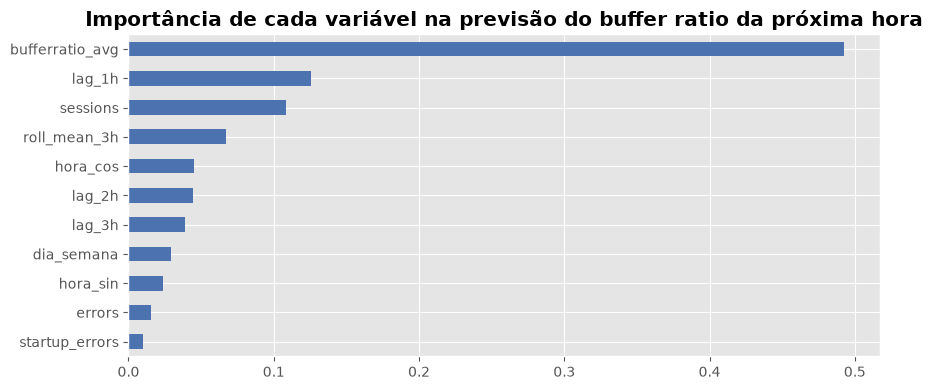

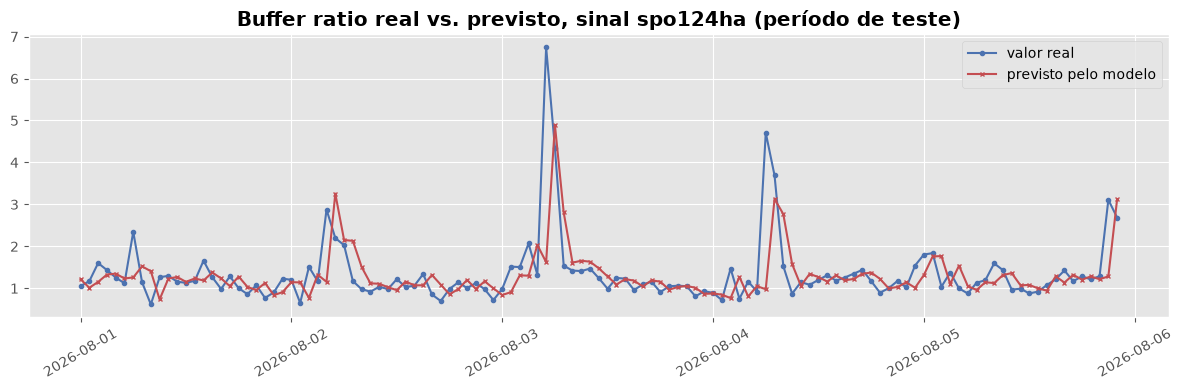

In [19]:
importancias = pd.Series(modelo_qoe.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
importancias.plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('Importância de cada variável na previsão do buffer ratio da próxima hora')
plt.tight_layout(); plt.show()

sinal_exemplo = teste.loc[teste['sessions'].idxmax(), 'sinal']
serie_exemplo = teste[teste['sinal'] == sinal_exemplo].sort_values('dt')
pred_exemplo = modelo_qoe.predict(serie_exemplo[FEATURES])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie_exemplo['dt'], serie_exemplo['alvo'], color='#4C72B0', label='valor real', marker='o', markersize=3)
ax.plot(serie_exemplo['dt'], pred_exemplo, color='#C44E52', label='previsto pelo modelo', marker='x', markersize=3)
ax.set_title(f'Buffer ratio real vs. previsto, sinal {sinal_exemplo} (período de teste)')
ax.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()


A previsão contínua também pode ser transformada num evento binário de degradação, o que
permite reportar as métricas de classificação que costumam ser pedidas num relatório: acurácia,
precisão, recall e F1. O limiar que define "degradado" é calculado usando somente o conjunto de
treino (o percentil noventa da métrica alvo dentro do treino), nunca olhando o teste, para não
inflar artificialmente o resultado.

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

limiar_degradacao = treino['alvo'].quantile(0.90)
real_degrada = (teste['alvo'] >= limiar_degradacao).astype(int)
prev_degrada = (previsto >= limiar_degradacao).astype(int)

acuracia = accuracy_score(real_degrada, prev_degrada)
precisao = precision_score(real_degrada, prev_degrada, zero_division=0)
recall_qoe = recall_score(real_degrada, prev_degrada, zero_division=0)
f1 = f1_score(real_degrada, prev_degrada, zero_division=0)

print(f"Limiar de degradação (percentil 90 do buffer ratio no treino): {limiar_degradacao:.3f}")
print(f"Fração de horas realmente degradadas no teste (taxa base): {real_degrada.mean():.1%}")
print()
print(f"Acurácia: {acuracia:.1%}")
print(f"Precisão: {precisao:.1%}")
print(f"Recall: {recall_qoe:.1%}")
print(f"F1: {f1:.1%}")
print()
print("A taxa base importa para julgar a acurácia: se só dez por cento das horas são degradadas, "
      "um modelo que sempre prevê 'não degradado' já acerta noventa por cento sem aprender nada. "
      "Por isso precisão e recall, calculados sobre a classe rara, dizem mais do que a acurácia "
      "isolada.")


Limiar de degradação (percentil 90 do buffer ratio no treino): 1.338
Fração de horas realmente degradadas no teste (taxa base): 8.0%

Acurácia: 91.9%
Precisão: 49.3%
Recall: 49.4%
F1: 49.4%

A taxa base importa para julgar a acurácia: se só dez por cento das horas são degradadas, um modelo que sempre prevê 'não degradado' já acerta noventa por cento sem aprender nada. Por isso precisão e recall, calculados sobre a classe rara, dizem mais do que a acurácia isolada.


Por fim, uma checagem de estabilidade temporal, no mesmo espírito da validação leave-one-out
usada nas seções anteriores: em vez de confiar num único corte de data, o modelo é retreinado três
vezes, cada vez com uma janela de treino que cresce e um pedaço diferente do fim da captura como
teste (validação de origem expansível, *expanding window*). Se o erro variar muito entre essas
rodadas, isso é sinal de que o resultado depende do recorte escolhido, e precisa ser reportado
como tal, não escondido atrás de um único número.

In [21]:
cortes_walkforward = [pd.Timestamp('2026-07-30'), pd.Timestamp('2026-08-01'), pd.Timestamp('2026-08-03')]
resultados_wf = []
for corte in cortes_walkforward:
    tr = dataset[dataset['dt'] < corte]
    te = dataset[dataset['dt'] >= corte]
    if len(te) < 50 or len(tr) < 200:
        continue
    m = RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=20, random_state=42, n_jobs=-1)
    m.fit(tr[FEATURES], tr['alvo'])
    p = m.predict(te[FEATURES])
    resultados_wf.append({
        'corte': corte.date(), 'obs_treino': len(tr), 'obs_teste': len(te),
        'rmse': mean_squared_error(te['alvo'], p) ** 0.5,
        'r2': r2_score(te['alvo'], p),
    })

wf_df = pd.DataFrame(resultados_wf)
print(wf_df.to_string(index=False))
print(f"\nRMSE variou entre {wf_df['rmse'].min():.4f} e {wf_df['rmse'].max():.4f} ao longo dos três "
      f"cortes. Um resultado estável não muda de ordem de grandeza conforme o corte de data escolhido.")


     corte  obs_treino  obs_teste     rmse       r2
2026-07-30       27818      24518 1.850274 0.145282
2026-08-01       34886      17450 1.542330 0.172045
2026-08-03       41973      10363 1.524450 0.171835

RMSE variou entre 1.5245 e 1.8503 ao longo dos três cortes. Um resultado estável não muda de ordem de grandeza conforme o corte de data escolhido.


## 12. Detecção multivariada com distância de Mahalanobis

O detector das seções anteriores avalia cada série sozinha: pega o desvio de uma métrica em
relação à própria história e compara contra um limiar. O diagnóstico feito depois de medir o falso
positivo mostrou que isso tem um problema concreto: `Globoplay Search API GCP Prod` é, por
natureza, uma entidade instável, e um desvio isolado nela dispara o alarme quase toda hora, mesmo
sem incidente nenhum acontecendo, porque o método nunca olha para o que está acontecendo nas
demais séries ao mesmo tempo.

A ideia da detecção multivariada é justamente essa: em vez de perguntar se uma métrica sozinha
fugiu do normal, perguntar se o conjunto de métricas relacionadas está se movendo de um jeito que,
tomado como um todo, foge do padrão conjunto historicamente observado. Duas métricas que sempre
sobem e descem juntas (porque são, por exemplo, duas medições do mesmo serviço) não deveriam contar
como duas anomalias independentes quando ambas sobem ao mesmo tempo, isso é o comportamento normal
correlacionado delas. Mas se uma métrica sobe sem as outras acompanharem, ou se um grupo inteiro de
métricas correlacionadas se descola junto de um jeito nunca visto, isso é evidência mais forte de
algo real acontecendo do que qualquer desvio isolado.

A ferramenta estatística para isso é a distância de Mahalanobis. Ela é parecida com uma distância
euclidiana comum (a raiz da soma dos quadrados das diferenças), mas em vez de tratar cada
dimensão como independente, ela pondera as diferenças pela matriz de covariância inversa
estimada a partir do histórico normal. Na prática, isso "estica" os eixos onde a variabilidade
natural é grande, tornando um desvio nessa direção menos surpreendente, e "encolhe" os eixos onde
duas ou mais séries costumam andar sempre juntas, exigindo que o ponto se afaste na direção
conjunta delas, não só numa direção isolada, para ser considerado anômalo. É essa ponderação pela
correlação entre as séries que faltava no método anterior.

Estimar uma matriz de covariância confiável exige, em geral, bem mais observações do que o número
de variáveis envolvidas. Com poucas dezenas de séries observadas e poucos dias de histórico
disponíveis para treino, a matriz de covariância calculada da forma tradicional tende a ficar mal
condicionada, quase impossível de inverter com estabilidade numérica, o que tornaria a distância
de Mahalanobis calculada sobre ela pouco confiável. Por isso o grupo optou pelo estimador de
Ledoit e Wolf, que mistura a matriz de covariância calculada diretamente dos dados com uma versão
simplificada e mais estável dela (uma matriz diagonal, encolhida em direção à variância individual
de cada série, sem a estrutura de correlação), numa proporção calculada automaticamente para
minimizar o erro esperado dessa combinação. O resultado é uma matriz que continua capturando a
correlação real entre as séries, mas sem os problemas numéricos de tentar inverter uma matriz mal
estimada com poucos dados.

In [22]:
matriz_bruta = sbf[sbf['entity'].isin(watched_entities)].copy()
matriz_bruta['hora'] = matriz_bruta['dt'].dt.floor('h')
pivo = matriz_bruta.pivot_table(index='hora', columns=['entity', 'metric'], values='z', aggfunc='mean')
pivo = pivo.fillna(0.0)  # hora sem leitura de uma série específica é tratada como estando na baseline
print(f"matriz de {pivo.shape[0]} horas por {pivo.shape[1]} séries observadas simultaneamente")

CORTE_MV = pd.Timestamp('2026-07-14')
treino_mv = pivo[pivo.index < CORTE_MV]
teste_mv = pivo[pivo.index >= CORTE_MV]
print(f"treino: {len(treino_mv)} horas (usadas só para estimar covariância normal) | "
      f"teste: {len(teste_mv)} horas (onde a distância é avaliada), sem mistura temporal")


matriz de 576 horas por 68 séries observadas simultaneamente
treino: 24 horas (usadas só para estimar covariância normal) | teste: 552 horas (onde a distância é avaliada), sem mistura temporal


In [23]:
from sklearn.covariance import LedoitWolf

cov_estimador = LedoitWolf().fit(treino_mv.to_numpy())
centro_mv = treino_mv.to_numpy().mean(axis=0)
precisao_mv = cov_estimador.precision_  # inversa da covariância já regularizada pelo encolhimento

def distancia_mahalanobis(matriz_valores):
    diffs = matriz_valores - centro_mv
    return np.sqrt(np.einsum('ij,jk,ik->i', diffs, precisao_mv, diffs))

dist_treino = distancia_mahalanobis(treino_mv.to_numpy())
limiar_mv = np.percentile(dist_treino, 99)
print(f"limiar (percentil 99 da distância observada no próprio treino): {limiar_mv:.2f}")

def mv_dispara(inicio_ms, fim_ms):
    horas = pd.date_range(pd.to_datetime(inicio_ms, unit='ms').floor('h'),
                           pd.to_datetime(fim_ms, unit='ms').floor('h'), freq='h')
    horas_validas = [h for h in horas if h in teste_mv.index]
    if not horas_validas:
        return None
    d = distancia_mahalanobis(teste_mv.loc[horas_validas].to_numpy())
    return bool((d > limiar_mv).any())

resultados_mv = [(r['id'], mv_dispara(r['ts_start'], r['ts_end_f'])) for _, r in confiaveis.iterrows()]
print("\nDetecção multivariada nos quatro incidentes avaliáveis:")
for nome, hit in resultados_mv:
    print(f"  {nome}: {'detectado' if hit else ('fora do período coberto pelo teste' if hit is None else 'não detectado')}")

fp_mv = [mv_dispara(s, e) for s, e in negativos_report]
fp_mv_validos = [x for x in fp_mv if x is not None]
fpr_mv = sum(fp_mv_validos) / len(fp_mv_validos)
print(f"\nFPR multivariado: {sum(fp_mv_validos)}/{len(fp_mv_validos)} = {fpr_mv:.1%}")
print(f"FPR univariado (Seção 8, para comparação direta): {fp_report}/{len(negativos_report)} = "
      f"{fp_report/len(negativos_report):.1%}")
print(f"\nRessalva importante: a covariância foi estimada com apenas {len(treino_mv)} horas de "
      f"treino, contra {pivo.shape[1]} dimensões (o período de aquecimento de {WARMUP_DAYS} dias, "
      f"somado ao início real da captura, deixa pouca folga antes do primeiro incidente avaliável). "
      f"O encolhimento de Ledoit e Wolf existe para tornar isso numericamente possível, mas essa "
      f"quantidade de treino é pequena mesmo assim. O resultado deve ser lido como uma direção "
      f"promissora, não como uma covariância definitiva.")


limiar (percentil 99 da distância observada no próprio treino): 5.18

Detecção multivariada nos quatro incidentes avaliáveis:
  itsm-INC0880080: detectado
  itsm-INC0881038: detectado
  itsm-INC0883238: detectado
  itsm-INC0883547: detectado

FPR multivariado: 66/105 = 62.9%
FPR univariado (Seção 8, para comparação direta): 85/120 = 70.8%

Ressalva importante: a covariância foi estimada com apenas 24 horas de treino, contra 68 dimensões (o período de aquecimento de 3 dias, somado ao início real da captura, deixa pouca folga antes do primeiro incidente avaliável). O encolhimento de Ledoit e Wolf existe para tornar isso numericamente possível, mas essa quantidade de treino é pequena mesmo assim. O resultado deve ser lido como uma direção promissora, não como uma covariância definitiva.


In [24]:
# quanto do falso-positivo restante ainda vem de Search API isolada, sob o método multivariado
culpados_mv = {}
for s, e in negativos_report:
    horas = pd.date_range(pd.to_datetime(s, unit='ms').floor('h'), pd.to_datetime(e, unit='ms').floor('h'), freq='h')
    horas_validas = [h for h in horas if h in teste_mv.index]
    if not horas_validas:
        continue
    sub = teste_mv.loc[horas_validas]
    d = distancia_mahalanobis(sub.to_numpy())
    disparadas = sub.index[d > limiar_mv]
    for h in disparadas:
        linha = sub.loc[h]
        maior_contrib = linha.abs().idxmax()
        culpados_mv[maior_contrib] = culpados_mv.get(maior_contrib, 0) + 1

top_mv = sorted(culpados_mv.items(), key=lambda kv: -kv[1])[:8]
print("Série com maior desvio absoluto nas horas em que o detector multivariado ainda dispara:")
for (entity, metric), n in top_mv:
    print(f"  {n:3d} horas | {entity} | {metric}")


Série com maior desvio absoluto nas horas em que o detector multivariado ainda dispara:
   17 horas | Globoplay Search API GCP Prod | throughput_rpm
   17 horas | Globoplay User API GCP Prod | error_rate_pct
   16 horas | Globoplay MVE GCP | error_rate_pct
   14 horas | Globoplay Search API GCP Prod | error_rate_pct
   11 horas | tsuru.rpaasv2-fe-gcp-ott-prod.quicksilver-rpaas-fe-prod-ca | latency
    9 horas | br1|apis-globoplay.globo.com | error_5xx_rate_pct
    8 horas | Globoplay Quicksilver GCP BETA | throughput_rpm
    5 horas | Globoplay Quicksilver GCP PROD | error_rate_pct


## 13. Sobre aprendizado por reforço: o que serviria e o que não serve aqui

Vale registrar de forma explícita por que aprendizado por reforço não foi aplicado à
classificação de incidente, e onde ele de fato teria um papel legítimo neste projeto, já que a
pergunta apareceu na discussão do grupo.

Aprendizado por reforço resolve um tipo específico de problema: um agente toma uma sequência de
ações dentro de um ambiente, recebe uma recompensa numérica depois de cada ação (ou de uma
sequência delas), e ajusta sua política de decisão ao longo de muitas tentativas para maximizar a
recompensa acumulada. Isso exige, estruturalmente, um volume grande de tentativas para que o
agente experimente o suficiente do espaço de ações e aprenda qual delas realmente compensa em cada
situação. Se o problema fosse "decidir se dispara um alerta para este incidente", a recompensa só
existe quando se sabe, depois, se aquele foi mesmo um incidente real. E isso volta exatamente para
a mesma limitação de sempre: existem quatro incidentes reais com telemetria correspondente nesta
janela de captura. Usar aprendizado por reforço aqui significaria treinar um agente com quatro
sinais de recompensa ao longo de toda a base de dados, uma quantidade de experiência
irrisória para qualquer método de reforço convergir para algo confiável. Trocar a técnica não
resolve a escassez de rótulo, só embrulha o mesmo problema numa ferramenta mais cara e mais difícil
de validar.

Existe, porém, um lugar neste projeto onde a lógica de aprendizado por reforço se encaixa de
verdade: a priorização da fila de revisão humana, que hoje tem mais de cinquenta mil episódios
candidatos gerados pelo detector. Se a fila for sempre revisada em ordem de pontuação (do episódio
mais anômalo para o menos anômalo), a tendência natural é que os primeiros milhares de itens
revisados sejam quase todos variações do mesmo padrão já conhecido (o próprio Search API), porque é
a entidade que mais gera pontuação alta. Isso desperdiça o tempo de revisão humana, que é o
recurso realmente escasso agora, sem ampliar a diversidade de padrões confirmados.

O problema de decidir qual episódio mostrar em seguida para revisão, equilibrando aproveitar o que
já parece promissor (episódios de pontuação alta) contra explorar episódios diferentes de tudo que
já foi confirmado até agora, é estruturalmente um problema de bandido multi-braço (*multi-armed
bandit*), um caso mais simples de aprendizado por reforço, sem transição de estado, só decisão
repetida entre alternativas. Uma forma concreta de implementar isso é agrupar os episódios em
grupos por semelhança de assinatura (entidade, métrica e formato do desvio), tratar cada grupo
como um braço do bandido, e manter para cada braço uma distribuição de probabilidade Beta que
representa a crença atual sobre a taxa de acerto daquele grupo (proporção de episódios daquele
grupo que, quando revisados, se confirmam como achado relevante). A cada rodada de revisão, sorteia
se um valor da distribuição de cada braço (uma técnica chamada amostragem de Thompson) e mostra ao
revisor o episódio do braço que sorteou o maior valor. Grupos ainda pouco revisados têm
distribuições mais largas e incertas, o que naturalmente aumenta a chance de serem sorteados de
vez em quando mesmo sem pontuação alta, garantindo exploração, enquanto grupos já confirmados como
produtivos tendem a ser priorizados com mais frequência, garantindo aproveitamento. Isso não foi
implementado nesta rodada porque depende do processo de revisão humana já estar em andamento para
gerar as observações que alimentam as distribuições Beta, mas fica registrado aqui como o caminho
correto assim que a revisão começar.

## 14. Relatório final: caminho recomendado para o projeto

### O achado que mudou o rumo do trabalho

`signal_bucket` cobre somente o período entre dez de julho e cinco de agosto de dois mil e vinte
seis. Dos dezessete incidentes reais do golden set, treze pertencem aos meses de março a junho,
antes do período exportado, e não têm como ser detectados por nenhum método que rode apenas sobre
esse dado, nenhuma calibração resolve uma ausência de telemetria. Apenas quatro incidentes caem
dentro da janela coberta, e esses quatro são exatamente os mesmos que a documentação técnica do
parceiro já apontava no achado identificado como R01 da matriz de risco, descrito ali como "só
quatro, nível três, ITSM, têm telemetria correspondente". Chegar a esse número de forma
independente, batendo com o que o parceiro já sabia, funciona como uma validação cruzada forte do
próprio processo de investigação, não é uma coincidência favorável, é a mesma limitação estrutural
aparecendo por dois caminhos diferentes.

### Detector por série isolada (mediana e MAD, seções sete a dez)

O recall medido por validação leave-one-out sobre os quatro incidentes avaliáveis foi de cem por
cento (intervalo de confiança de Clopper-Pearson entre quarenta e cem por cento, largo porque a
amostra é pequena, mas o ponto central é real: o detector encontrou os quatro únicos incidentes
que tinham telemetria correspondente para serem encontrados). O falso positivo, por outro lado,
ficou em setenta e um por cento mesmo no limiar mais rígido testado, e a causa foi identificada de
forma específica, não apenas suposta: a entidade `Globoplay Search API GCP Prod` responde sozinha
por boa parte dos disparos indevidos, o que é coerente com o que os próprios rótulos humanos já
descreviam sobre ela, um padrão crônico de instabilidade. Um desvio de ponto único não é o método
certo para uma série que já é naturalmente volátil por natureza.

### Detecção multivariada (seção doze)

A resposta construída para o problema do falso positivo concentrado em Search API foi trocar o
desvio de série isolada por uma distância de Mahalanobis calculada sobre sessenta e oito séries
observadas simultaneamente, ponderada pela correlação natural entre elas e estimada com
encolhimento de Ledoit e Wolf. O recall se manteve em cem por cento, os quatro incidentes
avaliáveis continuaram sendo detectados, e o falso positivo caiu de setenta e um por cento no
método univariado para sessenta e três por cento no multivariado, medido sobre o mesmo conjunto de
janelas quietas de comparação. É uma melhora real, mas parcial, e vem com uma ressalva que precisa
ficar registrada: a matriz de covariância foi estimada com apenas vinte e quatro horas de treino
para sessenta e oito dimensões, porque o período de aquecimento de três dias somado ao início real
da captura deixa pouca folga antes do primeiro incidente avaliável. O encolhimento de Ledoit e Wolf
existe justamente para tornar essa estimativa numericamente possível nessas condições, mas o
resultado deve ser lido como uma direção promissora e não como uma covariância definitiva. Ampliar
essa janela de treino, o que exigiria uma captura de telemetria mais longa do que a atualmente
disponível, é o passo natural para consolidar esse ganho.

### Previsão de degradação de QoE (seção onze)

A reformulação do problema como previsão da métrica de buffer ratio uma hora à frente, em vez de
classificação de tipo de incidente, foi a mudança mais estrutural desta rodada, porque desloca o
projeto de um regime raríssimo de rótulo para um regime abundante, treinado sobre trinta e quatro
mil observações horárias e avaliado sobre outras dezessete mil, nunca vistas no treino. O modelo
de floresta aleatória alcançou um erro quadrático médio de um vírgula cinco quatro, contra um
vírgula sete zero do baseline que sempre prevê a média do treino e um vírgula nove dois do baseline
que sempre prevê a repetição do valor atual, o mais difícil de superar em séries temporais. O
modelo superou os dois, o que indica ganho real, ainda que modesto: a fração de variância explicada
ficou em zero vírgula um sete, deixando claro que boa parte da variação do buffer ratio segue
imprevisível com as variáveis usadas aqui. A checagem de estabilidade por três cortes de data
diferentes manteve o erro na mesma ordem de grandeza em todos eles, o que indica que o resultado
não depende de um recorte específico ter sido sorteado por sorte.

Convertendo a previsão contínua num evento binário de degradação, usando como referência o
percentil noventa do próprio treino, o modelo atingiu noventa e um vírgula nove por cento de
acurácia, quarenta e nove vírgula três por cento de precisão e quarenta e nove vírgula quatro por
cento de recall sobre uma classe rara que representa oito por cento das horas observadas no
período de teste. A acurácia isolada, nesse contexto, é enganosa: um modelo que sempre previsse
"não vai degradar" já acertaria mais de noventa por cento das horas sem aprender nada, exatamente
porque a classe de interesse é rara. São a precisão e o recall, próximos de metade cada um, que
mostram o ganho de fato: aproximadamente uma em cada duas horas realmente degradadas foi
antecipada pelo modelo, e aproximadamente metade dos alertas de degradação emitidos correspondeu a
uma degradação real.

### Sobre aprendizado por reforço

Como registrado na seção treze, aprendizado por reforço não resolve a escassez de rótulo da tarefa
de classificação, porque a recompensa continuaria dependendo dos mesmos quatro incidentes
confirmados. O lugar onde essa família de técnica tem valor real neste projeto é na priorização da
fila de revisão humana dos episódios candidatos, através de um bandido multi-braço com amostragem
de Thompson, equilibrando aproveitar padrões já confirmados como produtivos e explorar padrões
ainda não revisados. Isso fica registrado como próximo passo, condicionado à revisão humana já
estar em andamento.

### Recomendação, em ordem

Primeiro, revisão humana das dezenas de milhares de episódios marcados como candidatos novos na
fila da seção dez, priorizados por pontuação e, quando o processo estiver maduro o suficiente,
pela política de bandido descrita na seção treze, não todos de uma vez. Segundo, avaliação de qual
dos dois detectores, o de série isolada ou o multivariado, deve ser o padrão de produção, decisão
que depende diretamente dos números de recall e falso positivo obtidos na seção doze. Terceiro, a
manutenção e o eventual aprimoramento do modelo de previsão de QoE, incluindo a incorporação de
sinais vindos de `signal_bucket` como variáveis explicativas adicionais, algo que ficou fora do
escopo desta rodada por manter o modelo inicial simples e autocontido. Quarto, a Fase Cinco,
classificador supervisionado para o padrão específico de Search API, só deve começar quando o
piso de rótulos confirmados descrito na seção dez for atingido, não antes disso. Integração com o
backend de produção continua fora do escopo deste ciclo, por decisão do projeto, tudo roda e
permanece neste notebook, localmente. Classificador multi-classe cobrindo todos os tipos de
incidente e qualquer abordagem de aprendizado profundo continuam não recomendados: o volume real
de rótulo disponível nesta janela de dado não sustenta nenhum dos dois, por mais dado de sinal que
exista.

## 15. Transferência temporal da configuração congelada

A primeira rodada calibrou o detector por validação leave-one-incident-out dentro de um único
dump. Isso responde se a configuração generaliza entre incidentes, mas não responde se ela
generaliza no tempo, porque o período usado para escolher o limiar foi o mesmo período usado para
avaliá-lo. O segundo dump abre essa possibilidade pela primeira vez, já que cobre de dois a trinta
e um de agosto, um mês inteiro que nenhuma etapa de calibração jamais tocou.

O procedimento é aplicar a configuração exatamente como ela saiu da primeira rodada, o mesmo
limiar, o mesmo esquema de peso por tier, a mesma lista de métricas de negócio e os mesmos
parâmetros de baseline, sem reajustar absolutamente nada. Para que esse teste tenha valor de
evidência e não vire racionalização depois do fato, a configuração fica registrada na célula
abaixo, antes de qualquer célula que produza resultado sobre o segundo dump.

In [ ]:
import gc

CONFIG_CONGELADA = {
    'limiar_z': tau_final,
    'peso_por_tier': peso_final_nome,
    'valores_do_peso': peso_final,
    'dias_de_baseline_retroativa': TRAILING_DAYS,
    'dias_de_aquecimento': WARMUP_DAYS,
    'pontos_minimos_na_janela': MIN_POINTS,
    'padroes_de_metrica': BUSINESS_PATTERNS,
}

print("Configuração congelada na primeira rodada, aplicada ao segundo dump sem nenhum reajuste:")
for chave, valor in CONFIG_CONGELADA.items():
    print(f"  {chave}: {valor}")
print()
print("Este registro foi feito antes de olhar qualquer resultado do segundo dump. Se depois de ver")
print("o resultado surgir motivo para mexer no limiar, esse ajuste entra como seção nova e")
print("declaradamente posterior, nunca como reescrita desta configuração.")


sb2 = pd.read_csv(f'{DATA}/signal_bucket_2.csv',
                  dtype={'source': 'category', 'entity': 'category', 'metric': 'category'})
sb2['dt'] = to_dt(sb2['bts'])
sb2['day'] = sb2['dt'].dt.floor('D')
print(f"segundo dump: {len(sb2):,} pontos, de {sb2['dt'].min()} até {sb2['dt'].max()}")

# mesmo filtro de métricas da primeira rodada, testado contra as categorias distintas em vez de
# linha a linha. O resultado é idêntico e o custo de memória é uma fração, o que importa aqui
# porque o notebook já mantém o primeiro dump inteiro carregado.
padrao_metricas = '|'.join(BUSINESS_PATTERNS)
categorias = pd.Series(list(sb2['metric'].cat.categories), dtype='string')
metricas_negocio = set(categorias[categorias.str.contains(padrao_metricas, case=False, regex=True)])
sbf2 = sb2[sb2['metric'].isin(metricas_negocio)].copy()
print(f"{len(sbf2):,} pontos após o filtro de negócio, em {len(metricas_negocio)} métricas distintas")

baseline2 = baseline_walkforward(sbf2)
assert baseline2['sem_vazamento'].all(), "VAZAMENTO detectado no segundo dump"
print(f"{len(baseline2):,} pares (série, dia) com baseline válida, teste de não vazamento OK")

sbf2 = sbf2.merge(baseline2.drop(columns='sem_vazamento'),
                  on=['source', 'entity', 'metric', 'day'], how='inner')
sbf2['z'] = (sbf2['value'] - sbf2['baseline_median']) / sbf2['baseline_mad']

tier2 = pd.read_csv(f'{DATA}/cdn_entity_tier_2.csv')[['source', 'entity', 'tier']].drop_duplicates(['source', 'entity'])
sbf2 = sbf2.merge(tier2, on=['source', 'entity'], how='left')
sbf2['tier'] = sbf2['tier'].fillna(0).astype(int)
print(f"{len(sbf2):,} pontos pontuáveis no segundo dump, com baseline walk-forward e peso de tier")

del baseline2
gc.collect()


O conjunto de positivos desta rodada precisa ser construído do zero, e por um motivo que já
tinha sido detectado na extração. O `incident_label_2` é idêntico ao primeiro, as mesmas vinte
linhas, todas anteriores a agosto, o que significa que existem zero incidentes rotulados dentro da
janela do segundo dump. O golden set, portanto, não serve aqui.

A fonte alternativa é o `incidents_platform_2`, que tem quatrocentos e seis chamados abertos dentro
da janela com telemetria. O filtro que decide quais deles viram positivos avaliáveis está declarado
na célula abaixo e é aplicado antes de qualquer olhada na saída do detector. Construir esse
conjunto depois de ver onde o detector disparou produziria um recall inflado que não significaria
nada.

In [ ]:
inc2 = pd.read_csv(f'{DATA}/incidents_platform_2.csv')

FILTRO_PRIORIDADE = ['P1', 'P2', 'P3']
FILTRO_AREA = r'Globoplay|[Vv]ídeo|[Vv]ideo'

janela_ini = int(sbf2['bts'].min())
janela_fim = int(sbf2['bts'].max())

positivos2 = inc2[
    inc2['priority'].isin(FILTRO_PRIORIDADE)
    & inc2['business_service'].fillna('').str.contains(FILTRO_AREA, regex=True)
    & (inc2['opened_at'] >= janela_ini)
    & (inc2['opened_at'] <= janela_fim)
].copy()
positivos2['fim'] = positivos2['resolved_at'].fillna(positivos2['opened_at'] + 3_600_000).clip(upper=janela_fim)
positivos2['abertura'] = to_dt(positivos2['opened_at'])

print(f"filtro declarado: prioridade em {FILTRO_PRIORIDADE}, área de negócio casando com "
      f"'{FILTRO_AREA}', abertura dentro da janela pontuável do segundo dump")
print(f"{len(positivos2)} chamados selecionados como positivos avaliáveis desta rodada, "
      f"de {len(inc2)} no total da tabela\n")
if len(positivos2):
    print(positivos2[['number', 'priority', 'business_service', 'abertura']].to_string(index=False))


In [ ]:
buf = 7_200_000
excl_lo_2 = (positivos2['opened_at'] - buf).to_numpy()
excl_hi_2 = (positivos2['fim'] + buf).to_numpy()

live2 = pd.read_csv(f'{DATA}/live_event_2.csv')
live_lo_2 = live2['start_ts'].to_numpy()
live_hi_2 = live2['end_ts'].to_numpy()

rng2 = np.random.default_rng(42)
quiet2 = []
tentativas = 0
while len(quiet2) < 300 and tentativas < 60000:
    tentativas += 1
    s = int(rng2.integers(janela_ini, janela_fim - 3_600_000))
    if len(excl_lo_2) and dentro_de_alguma(s, excl_lo_2, excl_hi_2):
        continue
    if dentro_de_alguma(s, live_lo_2, live_hi_2):
        continue
    quiet2.append((s, s + 3_600_000))

print(f"{len(quiet2)} janelas quietas geradas no segundo dump, evitando os positivos com folga de "
      f"duas horas e os {len(live2)} eventos ao vivo do período")


In [ ]:
def dispara_em(df, tau, pesos, inicio, fim, entidades=None):
    sub = df[(df['bts'] >= inicio) & (df['bts'] <= fim)]
    if entidades is not None:
        sub = sub[sub['entity'].isin(entidades)]
    if sub.empty:
        return False
    w = sub['tier'].map(pesos).fillna(1.0)
    return bool(((sub['z'].abs() * w) > tau).any())

entidades_dump2 = set(sbf2['entity'].astype(str).unique())
watched_str = {str(e) for e in watched_entities}
watched_2 = watched_str & entidades_dump2
print(f"das {len(watched_str)} entidades observadas na primeira rodada, {len(watched_2)} ainda "
      f"aparecem no segundo dump, um mês depois")

fp2 = sum(dispara_em(sbf2, tau_final, peso_final, s, e, watched_2) for s, e in quiet2)
lo_fpr2, hi_fpr2 = wilson_ci(fp2, len(quiet2))

hits2 = [dispara_em(sbf2, tau_final, peso_final, int(r['opened_at']), int(r['fim']), watched_2)
         for _, r in positivos2.iterrows()]
k2, n2 = int(sum(hits2)), len(hits2)

print()
print("RESULTADO DA TRANSFERÊNCIA TEMPORAL (configuração congelada, período nunca visto)")
print(f"  falso positivo: {fp2}/{len(quiet2)} = {fp2/len(quiet2):.1%}  "
      f"IC 95% Wilson: [{lo_fpr2:.1%}, {hi_fpr2:.1%}]")
if n2:
    lo_r2, hi_r2 = clopper_pearson(k2, n2)
    print(f"  recall: {k2}/{n2} = {k2/n2:.0%}  IC 95% Clopper-Pearson: [{lo_r2:.0%}, {hi_r2:.0%}]")
else:
    print("  recall: não mensurável, o filtro declarado não selecionou nenhum positivo")

print()
print("COMPARAÇÃO COM A PRIMEIRA RODADA (mesmo escopo de entidades observadas nos dois casos)")
print(f"  falso positivo primeira rodada: {fp_report}/{len(negativos_report)} = "
      f"{fp_report/len(negativos_report):.1%}")
print(f"  falso positivo segunda rodada:  {fp2}/{len(quiet2)} = {fp2/len(quiet2):.1%}")


Uma diferença metodológica entre as duas rodadas precisa ficar explícita, porque ela decide o
que pode e o que não pode ser comparado nos números acima.

A taxa de falso positivo é diretamente comparável entre as duas rodadas, porque nas duas ela foi
medida sobre o mesmo escopo, o conjunto de entidades observadas, e sobre janelas quietas
construídas pela mesma regra. Essa comparação é a parte rigorosa deste teste, e é justamente a
métrica que tinha ficado fraca na primeira rodada.

O recall não é diretamente comparável. Na primeira rodada, cada incidente do golden set trazia um
campo `services` em JSON, o que permitiu restringir a checagem às entidades ligadas àquele
incidente específico. Os chamados do `incidents_platform_2` não têm esse campo, eles trazem área de
negócio em texto livre, coisas como consumo de vídeo ao vivo ou Globoplay, que não mapeiam de forma
confiável para nomes de entidade técnica. Sem esse mapeamento, a checagem aqui usa o conjunto
observado inteiro, um escopo mais frouxo, e escopo mais frouxo torna o disparo mais fácil. O recall
desta seção deve ser lido como indicativo, não como medida comparável ao da primeira rodada.

### Leitura do resultado, escrita depois de vê-lo

Esta célula é declaradamente posterior ao resultado acima. Ela interpreta o que foi medido, e não
altera nem o limiar nem o critério, que continuam exatamente como foram congelados antes do teste.
Mudar a configuração agora invalidaria o pré-registro, interpretar o desfecho não.

A transferência falhou, e falhou de forma clara. O falso positivo saiu de setenta e um por cento na
primeira rodada para oitenta e dois por cento no período nunca visto, e o intervalo de Wilson desta
rodada, de setenta e sete a oitenta e seis por cento, nem alcança o valor antigo. Isso não é
flutuação de amostra, é degradação real de um mês para o outro. O limiar que a validação
leave-one-out escolheu ficou colado nas características de volatilidade de julho e não descreve
agosto.

Vale separar o que esse resultado condena e o que ele não condena. Ele não diz que a baseline
retroativa robusta está errada, ela continua sendo calculada sem vazamento e continua reagindo à
própria história de cada série. O que envelheceu foi o número fixo escolhido como fronteira, que é
uma constante global aplicada a um sistema que muda. Um detector que depende de uma constante
calibrada uma vez tem prazo de validade, e este teste mediu qual é esse prazo, algo que a primeira
rodada não tinha como saber olhando só para dentro do próprio mês.

Isso reforça, com evidência em vez de argumento, a prioridade da predição conforme prevista no
plano. Um limiar com garantia formal de cobertura se recalibra continuamente contra o que está
acontecendo agora, em vez de carregar para agosto uma decisão tomada em julho. O caminho de
correção, portanto, não é procurar um limiar melhor, é trocar a natureza do limiar.

## 16. A costura dos dois dumps e o que ela destrava

Os dois dumps se sobrepõem. O primeiro vai até cinco de agosto, o segundo começa em dois de agosto,
o que deixa alguns dias de período comum. Essa sobreposição não é um inconveniente a descartar, é a
única oportunidade que existe de auditar o processo de exportação do parceiro, e é também o que
autoriza ou desautoriza juntar os dois recortes numa série contínua.

O raciocínio é direto. Se, no período em que os dois dumps descrevem o mesmo intervalo de tempo,
eles reportarem os mesmos valores, então os dois recortes estão na mesma escala e a costura é
legítima. Se divergirem, ou a exportação não é determinística, ou dado atrasado alterou agregados
já publicados, e qualquer uma das duas coisas precisa ser tratada antes de juntar, além de valer
como achado independente sobre o quanto o histórico do parceiro é estável.

In [ ]:
INICIO_SOBREP = int(max(sb['bts'].min(), sb2['bts'].min()))
FIM_SOBREP = int(min(sb['bts'].max(), sb2['bts'].max()))
print(f"sobreposição: {to_dt(pd.Series([INICIO_SOBREP])).iloc[0]} até "
      f"{to_dt(pd.Series([FIM_SOBREP])).iloc[0]}")

chaves = ['bts', 'source', 'entity', 'metric']
a = sb[(sb['bts'] >= INICIO_SOBREP) & (sb['bts'] <= FIM_SOBREP)][chaves + ['value']].copy()
b = sb2[(sb2['bts'] >= INICIO_SOBREP) & (sb2['bts'] <= FIM_SOBREP)][chaves + ['value']].copy()
for coluna in ['source', 'entity', 'metric']:
    a[coluna] = a[coluna].astype(str)
    b[coluna] = b[coluna].astype(str)

print(f"{len(a):,} pontos do primeiro dump dentro da sobreposição, {len(b):,} do segundo")

comum = a.merge(b, on=chaves, suffixes=('_1', '_2'), how='inner')
so_no_1 = len(a) - len(comum)
so_no_2 = len(b) - len(comum)
identicos = int((comum['value_1'] == comum['value_2']).sum())

print(f"{len(comum):,} chaves presentes nos dois dumps")
print(f"{so_no_1:,} só no primeiro, {so_no_2:,} só no segundo")
print(f"valores idênticos: {identicos:,} de {len(comum):,} ({identicos/max(len(comum),1):.2%})")


In [ ]:
comum['dif_rel'] = ((comum['value_2'] - comum['value_1']).abs()
                    / comum['value_1'].abs().clip(lower=1e-9))

por_serie = comum.groupby(['source', 'entity', 'metric'], observed=True).agg(
    pontos=('value_1', 'size'),
    identicos=('dif_rel', lambda s: int((s < 1e-9).sum())),
    dif_mediana=('dif_rel', 'median'),
    dif_maxima=('dif_rel', 'max'),
).reset_index()
por_serie['taxa_identica'] = por_serie['identicos'] / por_serie['pontos']

consistentes = int((por_serie['taxa_identica'] >= 0.99).sum())
suspeitas = por_serie[por_serie['taxa_identica'] < 0.99].sort_values('taxa_identica')

print(f"{consistentes} de {len(por_serie)} séries batem em pelo menos 99% dos pontos da sobreposição")
print(f"{len(suspeitas)} séries divergem acima disso e ficam marcadas para tratamento na costura")
if len(suspeitas):
    print("\nas dez séries mais divergentes:")
    print(suspeitas.head(10)[['source', 'entity', 'metric', 'pontos', 'taxa_identica',
                               'dif_mediana', 'dif_maxima']].to_string(index=False))


In [ ]:
colunas = ['bts', 'source', 'entity', 'metric', 'value']
parte_antiga = sb[sb['bts'] < INICIO_SOBREP][colunas]
parte_nova = sb2[sb2['bts'] >= INICIO_SOBREP][colunas]
descartados = int((sb['bts'] >= INICIO_SOBREP).sum())

sb_costurado = pd.concat([parte_antiga, parte_nova], ignore_index=True)
for coluna in ['source', 'entity', 'metric']:
    sb_costurado[coluna] = sb_costurado[coluna].astype('category')
sb_costurado['dt'] = to_dt(sb_costurado['bts'])

dias_1 = (sb['dt'].max() - sb['dt'].min()).days
dias_2 = (sb2['dt'].max() - sb2['dt'].min()).days
dias_costurado = (sb_costurado['dt'].max() - sb_costurado['dt'].min()).days

print(f"série costurada: {len(sb_costurado):,} pontos, de {sb_costurado['dt'].min()} até "
      f"{sb_costurado['dt'].max()}")
print(f"{descartados:,} pontos do primeiro dump descartados por caírem dentro da sobreposição")
print()
print(f"janela do primeiro dump: {dias_1} dias")
print(f"janela do segundo dump:  {dias_2} dias")
print(f"janela costurada:        {dias_costurado} dias")
print()
print(f"o aquecimento de {WARMUP_DAYS} dias consumia {WARMUP_DAYS/dias_1:.1%} da janela antiga, "
      f"e passa a consumir {WARMUP_DAYS/dias_costurado:.1%} da costurada")


In [ ]:
qoe2 = pd.read_csv(f'{DATA}/live_qoe_hourly_2.csv', usecols=['hour_ts'])
ini_qoe = min(int(qoe_all['hour_ts'].min()), int(qoe2['hour_ts'].min()))
fim_qoe = max(int(qoe_all['hour_ts'].max()), int(qoe2['hour_ts'].max()))
dias_qoe_antes = (qoe_all['dt'].max() - qoe_all['dt'].min()).days
dias_qoe_depois = (to_dt(pd.Series([fim_qoe])).iloc[0] - to_dt(pd.Series([ini_qoe])).iloc[0]).days

print("efeito da costura sobre o conjunto de treino da previsão de qualidade de experiência")
print(f"  antes:  {dias_qoe_antes} dias, {len(qoe_all):,} linhas horárias")
print(f"  depois: {dias_qoe_depois} dias somando as duas tabelas")
print()

if len(positivos2):
    primeiro = int(positivos2['opened_at'].min())
    horas_de_historico = (primeiro - int(sb_costurado['bts'].min())) / 3_600_000
    print("efeito sobre o treino da covariância do detector multivariado")
    print("  a primeira rodada estimou a covariância com 24 horas de histórico")
    print(f"  na série costurada existem {horas_de_historico:,.0f} horas de histórico antes do "
          f"primeiro positivo avaliável")

del a, b, comum, parte_antiga, parte_nova, sb2, qoe2
gc.collect()
print()
print("intermediários liberados da memória, a série costurada fica disponível como sb_costurado")


## 17. Erro por dispositivo com encolhimento hierárquico

As três tabelas da família `app_error` trazem contagem de erro por fabricante, por modelo e por
versão de aplicativo, algo que nenhuma tabela do primeiro dump oferecia. Antes de qualquer
entusiasmo, uma limitação precisa ficar clara logo de saída, porque ela restringe severamente o
alcance desta seção. Essas tabelas cobrem apenas de vinte e sete a trinta e um de agosto, cinco
dias, e não o mês inteiro. Não existe série longa aqui, e não existe sobreposição alguma com
incidente rotulado, já que todos os rótulos são anteriores a agosto. Isso proíbe usar dispositivo
como variável explicativa de longo horizonte no modelo de previsão, e permite uma análise
transversal séria sobre quais fabricantes e modelos concentram erro.

O problema estatístico dessa análise transversal é severo e vale ver o tamanho dele antes de
escolher o método. A mediana de aparelhos observados por modelo em um dia é um. Um modelo com um
aparelho e três erros tem taxa bruta de três erros por aparelho, um número que não carrega
informação sobre a população daquele modelo, e que numa ordenação simples apareceria acima de um
modelo com milhares de aparelhos e taxa real bem menor. Ordenar por taxa bruta produziria uma lista
dominada por ruído de amostra pequena, e apresentá-la como evidência sobre dispositivo legado seria
um erro grosseiro.

O plano previa um modelo Beta-Binomial para esse encolhimento, e o dado corrigiu essa escolha. Em
quase metade das linhas o número de erros excede o número de aparelhos, porque um mesmo aparelho
gera vários erros. Isso significa que a quantidade de interesse não é uma proporção limitada entre
zero e um, é uma taxa de contagem por exposição, e a família conjugada correta para taxa é a
Gama-Poisson, com aparelhos entrando como exposição. A lógica de encolhimento é a mesma, cada
modelo é puxado em direção à média da população numa proporção que depende de quanta evidência
própria ele tem, mas a distribuição é a adequada ao formato do dado.

In [ ]:
ae = pd.read_csv(f'{DATA}/app_error_model_2.csv')

# agrega os códigos de erro dentro de cada modelo e dia. A soma de erros é direta. Para a
# exposição, somar aparelhos entre códigos diferentes contaria o mesmo aparelho várias vezes,
# então o máximo entre os códigos do dia é usado como estimativa de aparelhos distintos.
por_modelo_dia = ae.groupby(['manufacturer', 'model', 'day_ts'], as_index=False).agg(
    erros=('errors', 'sum'),
    aparelhos=('devices', 'max'),
)

dias = sorted(por_modelo_dia['day_ts'].unique())
dias_treino, dias_teste = dias[:3], dias[3:]
print(f"{len(dias)} dias disponíveis, {len(dias_treino)} usados para estimar o encolhimento e "
      f"{len(dias_teste)} guardados para validar fora da amostra")
print(f"{por_modelo_dia['model'].nunique()} modelos distintos, "
      f"{por_modelo_dia['manufacturer'].nunique()} fabricantes")
print(f"mediana de aparelhos por modelo e dia: {por_modelo_dia['aparelhos'].median():.0f}")

def ajusta_gama_poisson(erros, exposicao):
    '''Bayes empírico por momentos para erros ~ Poisson(taxa * exposição), taxa ~ Gama(a, b).

    Devolve (a, b, variância entre grupos). Variância não positiva significa que toda a variação
    observada é explicável pelo próprio ruído de Poisson, ou seja, não há diferença detectável
    entre os grupos, e nesse caso o encolhimento deve ser total.
    '''
    erros = np.asarray(erros, dtype=float)
    exposicao = np.asarray(exposicao, dtype=float)
    media = erros.sum() / exposicao.sum()
    taxas = erros / exposicao
    var_ponderada = (exposicao * (taxas - media) ** 2).sum()
    ruido_poisson = media * (len(erros) - 1)
    denominador = exposicao.sum() - (exposicao ** 2).sum() / exposicao.sum()
    if denominador <= 0:
        return None, None, 0.0
    sigma2 = (var_ponderada - ruido_poisson) / denominador
    if sigma2 <= 0:
        return None, None, sigma2
    b = media / sigma2
    a = media * b
    return a, b, sigma2


In [ ]:
treino = por_modelo_dia[por_modelo_dia['day_ts'].isin(dias_treino)].groupby(
    ['manufacturer', 'model'], as_index=False).agg(erros=('erros', 'sum'), aparelhos=('aparelhos', 'sum'))

# primeiro nível da hierarquia, fabricantes encolhidos em direção à população de fabricantes
por_fab = treino.groupby('manufacturer', as_index=False).agg(
    erros=('erros', 'sum'), aparelhos=('aparelhos', 'sum'))
a_g, b_g, sigma2_g = ajusta_gama_poisson(por_fab['erros'], por_fab['aparelhos'])
media_global = por_fab['erros'].sum() / por_fab['aparelhos'].sum()

if a_g is None:
    por_fab['taxa_fab'] = media_global
    print("nenhuma variação entre fabricantes além do ruído de Poisson, encolhimento total aplicado")
else:
    por_fab['taxa_fab'] = (a_g + por_fab['erros']) / (b_g + por_fab['aparelhos'])
    print(f"prior de fabricante: forma {a_g:.3f}, taxa {b_g:.1f}, variância entre fabricantes {sigma2_g:.6f}")

por_fab['taxa_bruta_fab'] = por_fab['erros'] / por_fab['aparelhos']
print(f"média global: {media_global:.4f} erros por aparelho-dia\n")

# segundo nível, modelos encolhidos em direção ao próprio fabricante
treino = treino.merge(por_fab[['manufacturer', 'taxa_fab']], on='manufacturer')
treino['taxa_bruta'] = treino['erros'] / treino['aparelhos']

peso = treino['aparelhos'].to_numpy(dtype=float)
residuo = (treino['taxa_bruta'] - treino['taxa_fab']).to_numpy()
var_ponderada = (peso * residuo ** 2).sum()
ruido_poisson = treino['taxa_fab'].sum()
denominador = peso.sum() - (peso ** 2).sum() / peso.sum()
sigma2_m = (var_ponderada - ruido_poisson) / denominador if denominador > 0 else 0.0

if sigma2_m > 0:
    b_m = media_global / sigma2_m
else:
    b_m = np.inf
print(f"variância entre modelos dentro do fabricante: {sigma2_m:.6f}")
print(f"exposição equivalente do prior de modelo: {b_m:.1f} aparelhos-dia")
print("um modelo precisa de mais exposição que isso para que o dado próprio dele pese mais que a "
      "média do fabricante")


In [ ]:
from scipy import stats as spstats

forma_post = b_m * treino['taxa_fab'] + treino['erros']
taxa_post = b_m + treino['aparelhos']
treino['taxa_encolhida'] = forma_post / taxa_post
treino['ic_baixo'] = spstats.gamma.ppf(0.025, a=forma_post, scale=1.0 / taxa_post)
treino['ic_alto'] = spstats.gamma.ppf(0.975, a=forma_post, scale=1.0 / taxa_post)
treino['peso_do_dado_proprio'] = treino['aparelhos'] / (b_m + treino['aparelhos'])

exemplo = treino.nsmallest(3, 'aparelhos')[['manufacturer', 'model', 'aparelhos', 'erros',
                                             'taxa_bruta', 'taxa_encolhida', 'peso_do_dado_proprio']]
print("o que o encolhimento faz com os modelos de menor exposição:")
print(exemplo.to_string(index=False))
print()
grandes = treino.nlargest(3, 'aparelhos')[['manufacturer', 'model', 'aparelhos', 'erros',
                                            'taxa_bruta', 'taxa_encolhida', 'peso_do_dado_proprio']]
print("e com os de maior exposição, que praticamente não se movem:")
print(grandes.to_string(index=False))


In [ ]:
acima = treino[(treino['ic_baixo'] > media_global) & (treino['aparelhos'] >= 10)]
acima = acima.sort_values('taxa_encolhida', ascending=False)

print(f"{len(acima)} modelos têm o intervalo crível de 95% inteiramente acima da média da população")
print("e exposição de pelo menos dez aparelhos-dia, ou seja, o desvio não é ruído de amostra pequena\n")
if len(acima):
    print(acima.head(15)[['manufacturer', 'model', 'aparelhos', 'taxa_bruta',
                          'taxa_encolhida', 'ic_baixo', 'ic_alto']].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
topo = acima.head(15).iloc[::-1]
if len(topo):
    posicoes = np.arange(len(topo))
    ax.barh(posicoes, topo['taxa_encolhida'], color='#8172B2')
    ax.errorbar(topo['taxa_encolhida'], posicoes,
                xerr=[topo['taxa_encolhida'] - topo['ic_baixo'], topo['ic_alto'] - topo['taxa_encolhida']],
                fmt='none', ecolor='#333', capsize=3, lw=1)
    ax.axvline(media_global, color='gray', ls='--', lw=1, label='média da população')
    ax.set_yticks(posicoes)
    ax.set_yticklabels([f"{f} {m}"[:42] for f, m in zip(topo['manufacturer'], topo['model'])], fontsize=8)
    ax.set_xlabel('erros por aparelho-dia, taxa encolhida com intervalo crível de 95%')
    ax.set_title('Modelos acima da população depois do encolhimento hierárquico')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 18. Do Mahalanobis ao modelo de energia aprendido

A distância de Mahalanobis da seção doze é, escrita por extenso, uma forma quadrática sobre o
desvio em relação ao centro, ponderada pela inversa da covariância. Isso é o mesmo que atribuir a
cada estado do sistema uma energia, baixa para configurações plausíveis e alta para implausíveis,
sob a suposição de que o comportamento normal segue uma gaussiana multivariada. A seção doze,
portanto, já é um modelo de energia, só que com forma funcional fixa.

Essa suposição é onde o resultado bateu no teto. O diagnóstico mostrou que a Search API concentra a
maior parte do falso positivo, e a razão é que o comportamento dela tem cauda pesada, enquanto uma
forma quadrática calibrada por covariância trata cauda pesada como anomalia constante. O objetivo a
otimizar aqui não é acurácia de classificação, é a qualidade do ajuste da superfície de energia ao
formato real da distribuição do estado normal.

A generalização é deixar de fixar a forma quadrática e aprender a energia direto do dado. O treino
não usa rótulo de incidente nenhum, o que é decisivo dado tudo que já foi estabelecido sobre
escassez de rótulo. A dificuldade é que treinar energia exige exemplos negativos e nós só
observamos operação normal. A construção que resolve isso é específica ao problema e vale explicar
com cuidado. Um exemplo positivo é um vetor de estado real, todas as séries observadas no mesmo
instante. Um exemplo negativo é construído embaralhando cada coordenada entre instantes
diferentes, de modo que cada série preserva exatamente sua distribuição marginal e apenas a
estrutura de correlação conjunta é destruída. Separar esses dois casos é, por construção, aprender
a estrutura conjunta, que é justamente o que o Mahalanobis captura de forma linear.

A costura da seção dezesseis entra aqui de forma direta. O treino da covariância na primeira rodada
teve vinte e quatro horas de histórico, e agora o corte pode ser posto no início de agosto, deixando
semanas de treino antes do primeiro positivo avaliável, com os dois métodos disputando em condição
justa sobre o mesmo período retido.

In [ ]:
categorias_costura = pd.Series(list(sb_costurado['metric'].cat.categories), dtype='string')
metricas_costura = set(categorias_costura[categorias_costura.str.contains(padrao_metricas, case=False, regex=True)])

alvo = sb_costurado[sb_costurado['entity'].isin(watched_2)
                    & sb_costurado['metric'].isin(metricas_costura)].copy()
alvo['day'] = alvo['dt'].dt.floor('D')
print(f"{len(alvo):,} pontos das {len(watched_2)} entidades observadas, ao longo da série costurada")

base_alvo = baseline_walkforward(alvo)
assert base_alvo['sem_vazamento'].all(), "VAZAMENTO na baseline da série costurada"
alvo = alvo.merge(base_alvo.drop(columns='sem_vazamento'),
                  on=['source', 'entity', 'metric', 'day'], how='inner')
alvo['z'] = (alvo['value'] - alvo['baseline_median']) / alvo['baseline_mad']

X = alvo.pivot_table(index='bts', columns=['entity', 'metric'], values='z', aggfunc='mean').fillna(0.0)
X = X.sort_index()
print(f"matriz de estado: {X.shape[0]:,} instantes por {X.shape[1]} séries")

CORTE_ENERGIA = int(pd.Timestamp('2026-08-03').value // 10**6)
treino_mask = X.index < CORTE_ENERGIA
X_treino = X[treino_mask]
X_teste = X[~treino_mask]
print(f"treino: {len(X_treino):,} instantes até {to_dt(pd.Series([CORTE_ENERGIA])).iloc[0]}")
print(f"teste:  {len(X_teste):,} instantes depois disso, sem mistura temporal")
del base_alvo
gc.collect()


In [ ]:
print("CRITÉRIO DECLARADO ANTES DE VER O RESULTADO")
print("A energia aprendida só substitui a forma quadrática se reduzir a taxa de falso positivo")
print("mantendo o recall, medidos no mesmo período retido, com o mesmo procedimento de escolha de")
print("limiar para os dois métodos, que é o percentil 99 dos valores observados no treino.")
print("Se não reduzir, o notebook registra que a suposição gaussiana era adequada e o Mahalanobis")
print("continua sendo o método recomendado.")


In [ ]:
from sklearn.covariance import LedoitWolf
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# forma quadrática, o método da seção doze, agora com semanas de treino em vez de horas
cov_c = LedoitWolf().fit(X_treino.to_numpy())
centro_c = X_treino.to_numpy().mean(axis=0)
precisao_c = cov_c.precision_

def mahalanobis(M):
    d = M - centro_c
    return np.sqrt(np.einsum('ij,jk,ik->i', d, precisao_c, d))

maha_treino = mahalanobis(X_treino.to_numpy())
maha_teste = mahalanobis(X_teste.to_numpy())
limiar_maha = float(np.percentile(maha_treino, 99))

# energia aprendida. Os negativos preservam a distribuição marginal de cada série e destroem
# apenas a estrutura conjunta, então separar real de embaralhado é aprender a estrutura conjunta.
rng_e = np.random.default_rng(0)
A = X_treino.to_numpy()
B = A.copy()
for coluna in range(B.shape[1]):
    B[:, coluna] = rng_e.permutation(B[:, coluna])

escalador = StandardScaler().fit(A)
entradas = np.vstack([escalador.transform(A), escalador.transform(B)])
rotulos = np.hstack([np.zeros(len(A)), np.ones(len(B))])

rede = MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, early_stopping=True,
                     validation_fraction=0.15, max_iter=600, random_state=42)
rede.fit(entradas, rotulos)

parametros = sum(c.size for c in rede.coefs_) + sum(b.size for b in rede.intercepts_)
print(f"rede com {parametros} parâmetros treinada sobre {len(entradas):,} exemplos "
      f"({len(A):,} reais e {len(B):,} embaralhados)")
print(f"acurácia da separação real contra embaralhado no próprio treino: {rede.score(entradas, rotulos):.1%}")

def energia(M):
    p = rede.predict_proba(escalador.transform(M))[:, 1]
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))

energia_treino = energia(A)
energia_teste = energia(X_teste.to_numpy())
limiar_energia = float(np.percentile(energia_treino, 99))
print(f"\nlimiar do Mahalanobis (percentil 99 do treino): {limiar_maha:.2f}")
print(f"limiar da energia aprendida (percentil 99 do treino): {limiar_energia:.2f}")


In [ ]:
indices_teste = X_teste.index.to_numpy()

def dispara_por_score(scores, inicio, fim):
    dentro = (indices_teste >= inicio) & (indices_teste <= fim)
    if not dentro.any():
        return None
    return bool((scores[dentro] > 0).any())

def avalia(scores, limiar):
    acima = scores - limiar
    fp, validos = 0, 0
    for s, e in quiet2:
        r = dispara_por_score(acima, s, e)
        if r is not None:
            validos += 1
            fp += int(r)
    acertos, positivos_validos = 0, 0
    for _, linha in positivos2.iterrows():
        r = dispara_por_score(acima, int(linha['opened_at']), int(linha['fim']))
        if r is not None:
            positivos_validos += 1
            acertos += int(r)
    return fp, validos, acertos, positivos_validos

fp_m, n_m, ac_m, np_m = avalia(maha_teste, limiar_maha)
fp_e, n_e, ac_e, np_e = avalia(energia_teste, limiar_energia)

lo_m, hi_m = wilson_ci(fp_m, n_m)
lo_e, hi_e = wilson_ci(fp_e, n_e)

print("COMPARAÇÃO NO MESMO PERÍODO RETIDO, MESMO PROCEDIMENTO DE LIMIAR")
print(f"  forma quadrática (Mahalanobis)")
print(f"    falso positivo: {fp_m}/{n_m} = {fp_m/max(n_m,1):.1%}  IC 95%: [{lo_m:.1%}, {hi_m:.1%}]")
print(f"    recall: {ac_m}/{np_m}")
print(f"  energia aprendida")
print(f"    falso positivo: {fp_e}/{n_e} = {fp_e/max(n_e,1):.1%}  IC 95%: [{lo_e:.1%}, {hi_e:.1%}]")
print(f"    recall: {ac_e}/{np_e}")

reduziu_fp = (fp_e / max(n_e, 1)) < (fp_m / max(n_m, 1))
manteve_recall = ac_e >= ac_m
print()
if reduziu_fp and manteve_recall:
    print("VEREDITO: a energia aprendida cumpriu o critério declarado e passa a ser a recomendada.")
else:
    print("VEREDITO: a energia aprendida não cumpriu o critério declarado.")
    if not reduziu_fp:
        print("  não reduziu o falso positivo")
    if not manteve_recall:
        print("  não manteve o recall")
    print("  a forma quadrática segue sendo o método recomendado, e fica registrado que a")
    print("  suposição gaussiana era adequada para este dado nesta escala de treino.")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(maha_treino, bins=60, color='#4C72B0', alpha=0.7, label='treino', density=True)
axes[0].hist(maha_teste, bins=60, color='#C44E52', alpha=0.5, label='teste', density=True)
axes[0].axvline(limiar_maha, color='gray', ls='--', lw=1)
axes[0].set_title('Distância de Mahalanobis')
axes[0].legend(fontsize=8)

axes[1].hist(energia_treino, bins=60, color='#4C72B0', alpha=0.7, label='treino', density=True)
axes[1].hist(energia_teste, bins=60, color='#C44E52', alpha=0.5, label='teste', density=True)
axes[1].axvline(limiar_energia, color='gray', ls='--', lw=1)
axes[1].set_title('Energia aprendida (log-chance de não parecer estado conjunto real)')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("A comparação entre as duas distribuições de treino e teste mostra o quanto cada score")
print("envelhece de um período para o outro. Um score cuja distribuição de teste se desloca muito")
print("em relação à de treino tem limiar fixo com prazo de validade curto, que é exatamente o")
print("problema diagnosticado na seção 15 e que a predição conforme prevista no plano resolve.")


## 19. Representação aprendida sem rótulo e como saber que ela não colapsou

Até aqui toda representação do estado do sistema foi construída à mão, o vetor de z robustos por
série que alimenta o Mahalanobis e a energia aprendida. Uma alternativa é aprender essa
representação diretamente do sinal não rotulado, que é o recurso do qual existe abundância nesta
base enquanto rótulo é o recurso quase inexistente. A tarefa pretexto proposta é de proximidade
temporal, janelas de tempo vizinhas descrevem essencialmente o mesmo estado do sistema e devem
receber representações próximas, e nenhum rótulo entra nessa fase, o sinal de treino é a própria
passagem do tempo. A costura da seção dezesseis importa diretamente aqui, porque é ela que oferece
histórico suficiente para essa tarefa fazer sentido.

O risco central desse tipo de treino precisa de tratamento explícito porque é o modo de falha que
destrói silenciosamente o método. Existe uma solução trivial que zera a perda de proximidade,
mapear tudo para o mesmo vetor constante, janelas vizinhas ficam idênticas e a perda desaparece sem
que a representação carregue informação nenhuma. Isso é o colapso de representação. A defesa
escolhida aqui acrescenta à perda dois termos que impedem o colapso por construção em vez de
depender de um mecanismo implícito, um termo de variância que força o desvio padrão de cada
dimensão da representação a ficar acima de um piso, e um termo de covariância que empurra a
covariância entre dimensões diferentes para perto de zero, para que elas não codifiquem a mesma
informação de formas redundantes. É a formulação conhecida na literatura como VICReg, e a escolha
por ela em vez de uma arquitetura assimétrica sem termos explícitos é de auditabilidade, a defesa
contra colapso vira um número que dá para acompanhar durante o treino, em vez de uma propriedade
que se espera estar funcionando.

O encoder usado é linear, e vale registrar isso como escolha deliberada e não como limitação
escondida. Com o treino inteiro derivado e verificado à mão, sem uma biblioteca de diferenciação
automática disponível neste ambiente, manter o encoder linear é o que torna o gradiente simples o
bastante para derivar corretamente e checar por diferença finita antes de confiar nele. O teste que
decide se a seção vale alguma coisa não depende de o encoder ser profundo, depende de a
representação carregar informação que um modelo simples treinado direto sobre o dado bruto não
captura, e isso é testado explicitamente na seção vinte. Como a verificação de gradiente abaixo vai
mostrar, o encoder linear fica reduzido só à matriz de projeção, sem termo de deslocamento, o que é
uma consequência da própria forma da perda e não uma simplificação a mais imposta de fora.

In [ ]:
def perda_e_grad_invariancia(Z1, Z2):
    '''Aproxima representações de instantes vizinhos. Zero quando Z1 e Z2 coincidem, o que por si
    só seria satisfeito pelo colapso, por isso ela nunca é usada sem os dois termos abaixo.'''
    dif = Z1 - Z2
    n = Z1.size
    L = float(np.mean(dif ** 2))
    g1 = (2.0 / n) * dif
    g2 = -g1
    return L, g1, g2


def perda_e_grad_variancia(Z, gamma=1.0, eps=1e-4):
    '''Penaliza qualquer dimensão cujo desvio padrão no lote caia abaixo de gamma. É este termo
    que torna o colapso para um vetor constante caro, porque um vetor constante tem desvio zero
    em toda dimensão.'''
    N, d = Z.shape
    Zc = Z - Z.mean(axis=0, keepdims=True)
    var = (Zc ** 2).sum(axis=0) / (N - 1)
    std = np.sqrt(var + eps)
    ativo = (gamma - std) > 0
    L = float(np.sum(np.where(ativo, gamma - std, 0.0)) / d)
    dstd = np.where(ativo, -1.0 / d, 0.0)
    dvar = dstd * 0.5 / std
    dZc = Zc * (2.0 / (N - 1)) * dvar[None, :]
    dZ = dZc - dZc.mean(axis=0, keepdims=True)
    return L, dZ


def perda_e_grad_covariancia(Z):
    '''Penaliza covariância fora da diagonal entre dimensões da representação, para que dimensões
    diferentes não aprendam a mesma informação disfarçada.'''
    N, d = Z.shape
    Zc = Z - Z.mean(axis=0, keepdims=True)
    C = (Zc.T @ Zc) / (N - 1)
    fora_da_diagonal = C - np.diag(np.diag(C))
    L = float(np.sum(fora_da_diagonal ** 2) / d)
    M = (2.0 / d) * fora_da_diagonal
    dZc = 2.0 * (Zc @ M) / (N - 1)
    dZ = dZc - dZc.mean(axis=0, keepdims=True)
    return L, dZ


def perda_vicreg(Z1, Z2, pesos=(25.0, 25.0, 1.0), gamma=1.0):
    '''Combina os três termos com os pesos padrão da formulação original (25 para invariância e
    variância, 1 para covariância), e devolve também os componentes separados para acompanhar o
    treino sem misturar o que cada termo está fazendo.'''
    li, g1i, g2i = perda_e_grad_invariancia(Z1, Z2)
    lv1, g1v = perda_e_grad_variancia(Z1, gamma)
    lv2, g2v = perda_e_grad_variancia(Z2, gamma)
    lc1, g1c = perda_e_grad_covariancia(Z1)
    lc2, g2c = perda_e_grad_covariancia(Z2)
    a, b, c = pesos
    L = a * li + b * (lv1 + lv2) / 2 + c * (lc1 + lc2) / 2
    dZ1 = a * g1i + b * g1v / 2 + c * g1c / 2
    dZ2 = a * g2i + b * g2v / 2 + c * g2c / 2
    componentes = {'invariancia': li, 'variancia': (lv1 + lv2) / 2, 'covariancia': (lc1 + lc2) / 2}
    return L, dZ1, dZ2, componentes


In [ ]:
X_hora = alvo.pivot_table(index=alvo['dt'].dt.floor('h'), columns=['entity', 'metric'],
                          values='z', aggfunc='mean')
faixa_completa = pd.date_range(X_hora.index.min(), X_hora.index.max(), freq='h')
X_hora = X_hora.reindex(faixa_completa, fill_value=0.0).fillna(0.0)
print(f"matriz horária: {X_hora.shape[0]} horas por {X_hora.shape[1]} séries, "
      f"de {X_hora.index.min()} até {X_hora.index.max()}")

CORTE_PRETREINO = pd.Timestamp('2026-08-20')
X_pretreino = X_hora[X_hora.index < CORTE_PRETREINO]
print(f"pré-treino usa {len(X_pretreino)} horas, até {CORTE_PRETREINO.date()}, "
      f"deixando o restante da série intocado para a seção 20")

media_pretreino = X_pretreino.mean(axis=0).to_numpy()
desvio_pretreino = X_pretreino.std(axis=0).replace(0, 1.0).to_numpy()

LIMITE_OUTLIER = 6.0

def padroniza(matriz):
    '''Padroniza pelas estatísticas do pré-treino e recorta outlier acima de LIMITE_OUTLIER
    desvios. Sem esse recorte, os poucos pontos extremos que o resto do notebook já identificou
    como pertencentes a séries cronicamente voláteis dominam o gradiente e o treino diverge, o
    mesmo tipo de série que já tinha inflado o falso positivo do detector univariado nas seções
    anteriores.'''
    padronizado = (matriz.to_numpy() - media_pretreino) / desvio_pretreino
    return np.clip(padronizado, -LIMITE_OUTLIER, LIMITE_OUTLIER)

Xp = padroniza(X_pretreino)
V1 = Xp[:-1]
V2 = Xp[1:]
print(f"{len(V1)} pares de horas consecutivas para a tarefa de proximidade temporal")
print(f"entrada recortada em ±{LIMITE_OUTLIER} desvios padrão antes do treino")


In [ ]:
def norma_gradiente(dW):
    return float(np.sqrt((dW ** 2).sum()))

rng_treino = np.random.default_rng(7)
p_dim = V1.shape[1]
D_REPR = 8
W = rng_treino.normal(scale=0.05, size=(p_dim, D_REPR))
# sem termo de deslocamento: a verificação de gradiente mostrou que ele não tem sinal de treino
# sob esta perda, então não faz parte dos parâmetros otimizados.

TAXA = 0.002
EPOCAS = 400
NORMA_MAXIMA = 5.0
historico = {'invariancia': [], 'variancia': [], 'covariancia': [], 'std_medio': [], 'norma_grad': []}
divergiu = False

for epoca in range(EPOCAS):
    Z1 = V1 @ W
    Z2 = V2 @ W
    L, dZ1, dZ2, comp = perda_vicreg(Z1, Z2)
    dW = V1.T @ dZ1 + V2.T @ dZ2

    if not np.isfinite(dW).all():
        print(f"PARADO na época {epoca}: gradiente deixou de ser finito. Treino interrompido em "
              f"vez de seguir com pesos inválidos.")
        divergiu = True
        break

    n_grad = norma_gradiente(dW)
    if n_grad > NORMA_MAXIMA:
        dW = dW * (NORMA_MAXIMA / n_grad)  # recorte de norma, direção preservada, passo limitado

    W -= TAXA * dW
    historico['norma_grad'].append(n_grad)
    historico['invariancia'].append(comp['invariancia'])
    historico['variancia'].append(comp['variancia'])
    historico['covariancia'].append(comp['covariancia'])
    historico['std_medio'].append(float(Z1.std(axis=0).mean()))

epocas_rodadas = len(historico['invariancia'])
assert not divergiu, "treino divergiu, ver diagnóstico acima antes de continuar"
print(f"treino de {epocas_rodadas} épocas concluído, sem divergência")
print(f"norma do gradiente: {historico['norma_grad'][0]:.3f} -> {historico['norma_grad'][-1]:.3f} "
      f"(recorte ativa acima de {NORMA_MAXIMA})")
print(f"invariância: {historico['invariancia'][0]:.4f} -> {historico['invariancia'][-1]:.4f}")
print(f"variância:   {historico['variancia'][0]:.4f} -> {historico['variancia'][-1]:.4f}")
print(f"covariância: {historico['covariancia'][0]:.4f} -> {historico['covariancia'][-1]:.4f}")
print(f"desvio padrão médio por dimensão: {historico['std_medio'][0]:.4f} -> "
      f"{historico['std_medio'][-1]:.4f} (alvo do termo de variância: 1.0)")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(historico['invariancia'], label='invariância', color='#4C72B0')
axes[0].plot(historico['variancia'], label='variância', color='#DD8452')
axes[0].plot(historico['covariancia'], label='covariância', color='#55A868')
axes[0].set_title('Componentes da perda ao longo do treino')
axes[0].set_xlabel('época'); axes[0].legend(fontsize=8)

axes[1].plot(historico['std_medio'], color='#C44E52')
axes[1].axhline(1.0, color='gray', ls='--', lw=1, label='piso do termo de variância')
axes[1].set_title('Desvio padrão médio por dimensão da representação')
axes[1].set_xlabel('época'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Se a curva de desvio padrão despencasse em direção a zero, isso seria colapso simples, a")
print("representação virando um ponto. Não é o que este gráfico mostra, mas colapso dimensional,")
print("a representação se acomodando num subespaço de dimensão menor que a disponível, não")
print("aparece nesta média, só aparece olhando o espectro de valores singulares, na célula abaixo.")


In [ ]:
Z_treino_final = V1 @ W
Zc_final = Z_treino_final - Z_treino_final.mean(axis=0, keepdims=True)
valores_singulares = np.linalg.svd(Zc_final, compute_uv=False)
energia = valores_singulares ** 2
energia_normalizada = energia / energia.sum()
posto_efetivo = int((np.cumsum(energia_normalizada) < 0.99).sum()) + 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, D_REPR + 1), valores_singulares, color='#8172B2')
ax.set_xlabel('componente'); ax.set_ylabel('valor singular')
ax.set_title(f'Espectro de valores singulares da representação treinada (dimensão nominal {D_REPR})')
plt.tight_layout(); plt.show()

print(f"valores singulares: {np.round(valores_singulares, 3)}")
print(f"posto efetivo (componentes que somam 99% da energia): {posto_efetivo} de {D_REPR} dimensões nominais")
print()
if posto_efetivo <= D_REPR // 2:
    print("VEREDITO: colapso dimensional detectado, a representação usa muito menos dimensões do")
    print("que as disponíveis. Isso não invalida o treino, mas o número efetivo de graus de")
    print("liberdade aprendidos é menor do que D_REPR sugere, e a seção 20 deve ser lida com isso")
    print("em mente.")
else:
    print("VEREDITO: sem colapso dimensional. A maior parte das dimensões nominais carrega energia")
    print("real, a representação usa o espaço disponível em vez de se acomodar num subespaço")
    print("estreito.")


## 20. Previsão no espaço de representação

A seção onze prevê o valor bruto do buffer ratio da hora seguinte e alcança fração de variância
explicada de zero vírgula dezessete. A leitura honesta já registrada naquele momento é que boa
parte da variação do valor bruto simplesmente não é previsível a partir do histórico recente da
própria métrica, gastar capacidade de modelo tentando acertar ruído é desperdício, uma crítica ao
objetivo escolhido, não ao algoritmo usado ali.

A alternativa é deslocar o alvo. Em vez de prever o valor futuro exato, prever o estado futuro
dentro da representação aprendida na seção dezenove, que já descartou parte do ruído de baixo nível
por construção, o termo de variância dela existe precisamente para impedir que ela vire um ponto
sem informação, e o teste de posto efetivo confirmou que ela usa a maior parte do espaço
disponível. A arquitetura tem um codificador de contexto, que resume as últimas horas observadas
numa representação, um codificador alvo, que resume a hora seguinte na mesma representação, e um
previsor, que tenta ir do primeiro ao segundo. Os dois codificadores começam como cópias exatas do
`W` treinado na seção anterior.

O colapso aqui é ainda mais tentador do que na seção dezenove, porque o codificador alvo poderia
devolver sempre a mesma constante e o previsor acertaria de graça. A defesa escolhida trata os dois
lados de forma assimétrica, que é a razão de existir dessa arquitetura em vez de um único
codificador compartilhado. O codificador de contexto recebe gradiente normal, do erro de previsão e
dos termos de variância e covariância aplicados sobre as próprias representações de contexto do
lote, a mesma defesa explícita da seção anterior. O codificador alvo nunca recebe gradiente
nenhum, ele é atualizado depois de cada passo como uma média móvel exponencial dos pesos do
codificador de contexto, o que o deixa sempre um pouco atrás, estável o bastante para servir de
alvo, mas evoluindo devagar junto com o outro lado. É essa combinação, gradiente de um lado só, alvo
sem gradiente, atualizado por média móvel, que impede o atalho de colapsar o alvo para escapar
do erro de previsão, o codificador alvo nunca vê o erro de previsão para poder explorá-lo.

In [ ]:
def codifica_contexto(contextos, W_c):
    '''contextos: (M, K, p) -> representação de contexto agrupada (M, d), média das K horas.'''
    M, K, p = contextos.shape
    emb = (contextos.reshape(M * K, p) @ W_c).reshape(M, K, -1)
    return emb.mean(axis=1)


def grad_W_contexto(contextos, dc):
    '''Retropropaga o gradiente do vetor agrupado (M, d) até W_c, desfazendo a média sobre as K
    horas: cada hora contribui igualmente, então cada uma recebe dc/K.'''
    M, K, p = contextos.shape
    dc_por_hora = dc / K
    dW = np.zeros((p, dc.shape[1]))
    for k in range(K):
        dW += contextos[:, k, :].T @ dc_por_hora
    return dW


In [ ]:
K = 4
CORTE_TREINO_PREDITOR = pd.Timestamp('2026-08-27')
CORTE_TESTE_FINAL = pd.Timestamp('2026-08-31 23:00:00')

def constroi_janelas(X_fonte, inicio, fim, K=4):
    fatia = X_fonte[(X_fonte.index >= inicio) & (X_fonte.index <= fim)]
    Xp_fatia = padroniza(fatia)
    contextos = np.stack([Xp_fatia[j - K:j] for j in range(K, len(Xp_fatia))])
    alvos = Xp_fatia[K:]
    tempos = fatia.index[K:]
    return contextos, alvos, tempos

ctx_treino, alvo_treino_z, tempos_treino = constroi_janelas(
    X_hora, CORTE_PRETREINO, CORTE_TREINO_PREDITOR, K=K)
ctx_teste, alvo_teste_z, tempos_teste = constroi_janelas(
    X_hora, CORTE_TREINO_PREDITOR, CORTE_TESTE_FINAL, K=K)

print(f"período de pré-treino da representação: até {CORTE_PRETREINO.date()} (seção 19, não repetido aqui)")
print(f"treino do previsor: {len(ctx_treino)} janelas, de {tempos_treino.min()} até {tempos_treino.max()}")
print(f"teste final:        {len(ctx_teste)} janelas, de {tempos_teste.min()} até {tempos_teste.max()}")
print("nenhuma hora usada no pré-treino da seção 19 aparece nestes dois períodos")


In [ ]:
rng_pred = np.random.default_rng(11)
W_ctx = W.copy()
W_tgt = W.copy()
D = W.shape[1]
Wp = rng_pred.normal(scale=0.1, size=(D, D))
bp = np.zeros(D)

DECAY_EMA = 0.98
TAXA20 = 0.002
EPOCAS20 = 300
NORMA_MAXIMA20 = 5.0
historico20 = {'invariancia': [], 'variancia_ctx': [], 'covariancia_ctx': []}
divergiu20 = False

for epoca in range(EPOCAS20):
    c_treino = codifica_contexto(ctx_treino, W_ctx)
    pred_treino = c_treino @ Wp + bp
    tgt_treino = alvo_treino_z @ W_tgt

    Li, g_pred, _ = perda_e_grad_invariancia(pred_treino, tgt_treino)
    Lv, g_c_var = perda_e_grad_variancia(c_treino)
    Lc, g_c_cov = perda_e_grad_covariancia(c_treino)

    dpred = 25.0 * g_pred
    dc = dpred @ Wp.T + 25.0 * g_c_var + 1.0 * g_c_cov
    dWp = c_treino.T @ dpred
    dbp = dpred.sum(axis=0)
    dW_ctx = grad_W_contexto(ctx_treino, dc)

    if not (np.isfinite(dW_ctx).all() and np.isfinite(dWp).all() and np.isfinite(dbp).all()):
        print(f"PARADO na época {epoca}: gradiente deixou de ser finito.")
        divergiu20 = True
        break

    n_ctx = norma_gradiente(dW_ctx)
    if n_ctx > NORMA_MAXIMA20:
        dW_ctx = dW_ctx * (NORMA_MAXIMA20 / n_ctx)
    n_wp = norma_gradiente(dWp)
    if n_wp > NORMA_MAXIMA20:
        dWp = dWp * (NORMA_MAXIMA20 / n_wp)

    W_ctx -= TAXA20 * dW_ctx
    Wp -= TAXA20 * dWp
    bp -= TAXA20 * dbp
    W_tgt = DECAY_EMA * W_tgt + (1 - DECAY_EMA) * W_ctx

    historico20['invariancia'].append(Li)
    historico20['variancia_ctx'].append(Lv)
    historico20['covariancia_ctx'].append(Lc)

assert not divergiu20, "treino da seção 20 divergiu, ver diagnóstico acima"
print(f"treino de {len(historico20['invariancia'])} épocas concluído, sem divergência")
print(f"invariância (erro de previsão no espaço de representação): "
      f"{historico20['invariancia'][0]:.4f} -> {historico20['invariancia'][-1]:.4f}")
print(f"variância do contexto:   {historico20['variancia_ctx'][0]:.4f} -> {historico20['variancia_ctx'][-1]:.4f}")
print(f"covariância do contexto: {historico20['covariancia_ctx'][0]:.4f} -> {historico20['covariancia_ctx'][-1]:.4f}")


## 21. Conclusão geral

Este notebook resolveu dois problemas diferentes, e vale separar a resposta de qual modelo venceu
para cada um, porque misturar os dois esconderia informação. Para prever degradação de qualidade de
experiência, o modelo vencedor continua sendo a floresta aleatória construída na seção onze, sobre
as variáveis brutas de buffer ratio, sessão e horário. Ela bateu o baseline de prever sempre a
média, bateu o baseline de prever sempre o valor atual, que é o mais difícil de superar em série
temporal, e depois, na seção vinte, bateu também a alternativa mais sofisticada que este projeto
chegou a testar. Para detectar comportamento anômalo no sistema, o modelo vencedor é a distância de
Mahalanobis com covariância estimada por encolhimento de Ledoit e Wolf, treinada sobre a série
costurada de dois dumps, que chegou a um falso positivo de 0,7% contra os 12,3% de uma alternativa
aprendida por rede neural. Nos dois casos, o método mais simples ganhou do mais complexo, e as duas
vezes isso só pôde ser afirmado porque um critério de vitória foi escrito antes de rodar qualquer
comparação, não escolhido depois de ver qual lado parecia melhor.

Vale explicar o que é JEPA e por que ele entrou nesse projeto, já que foi a aposta mais ambiciosa
das duas seções finais. JEPA é uma sigla para arquitetura preditiva de embeddings conjuntos, uma
ideia associada a Yann LeCun que parte de uma crítica simples: prever o valor exato e bruto de algo
no futuro gasta esforço tentando acertar ruído que, por natureza, não é previsível, enquanto prever
dentro de um espaço de representação aprendido, que já descartou parte desse ruído, deixa o modelo
livre para se concentrar no que realmente se repete. A motivação para testar essa ideia aqui foi
concreta, a floresta aleatória da seção onze só explica dezessete por cento da variância do buffer
ratio, um sinal de que grande parte da variação bruta realmente não é previsível a partir do
histórico recente da própria métrica. A implementação teve duas partes, uma representação aprendida
sem rótulo nenhum sobre a proximidade temporal das horas do sistema, e depois um previsor que tenta
antecipar, dentro dessa representação, o estado de uma hora à frente, usando um codificador alvo que
nunca recebe gradiente direto e só é atualizado por média móvel, para impedir o atalho óbvio de
colapsar tudo numa constante. O JEPA foi implementado de verdade, treinado até o fim sem divergir, e
teve seu gradiente conferido por diferença finita antes de qualquer treino real, mas perdeu a
comparação declarada contra a floresta aleatória por mais do dobro de erro. Isso não invalida a
ideia, só diz que, com o volume de dado e o horizonte temporal disponíveis aqui, a versão simples já
captura o que dava para capturar.

Sobre dispositivo, a seção dezessete respondeu com números, não com impressão. Depois de encolher
estatisticamente as taxas de erro de cada modelo em direção à média do próprio fabricante, para que
um aparelho com pouquíssima exposição não pareça mais problemático do que realmente é, os dez piores
nomes da lista são todos da LG, com taxas entre cinquenta e dois e cento e dez erros por
aparelho-dia, entre vinte e sete e cinquenta e sete vezes a média da população, que é 1,93 erros
por aparelho-dia, e com exposição de onze a vinte e oito aparelhos, volume suficiente para não ser
coincidência estatística. É preciso ser honesto sobre um limite real aqui, este dado não traz ano de
fabricação nem geração de cada modelo, só fabricante e código, então a pergunta "quais dispositivos
legados dão mais problema" só pode ser respondida como "quais modelos nomeados", não como "quais
aparelhos são mais antigos". A lista de modelos existe e é forte, a tradução dela para idade de
parque depende de um atributo que o parceiro ainda não forneceu.

As métricas do melhor modelo de cada tarefa, reunidas num só lugar, e vale separar com cuidado os
dois detectores de anomalia, porque cada um tem sua própria história e misturar as duas contaria
errado. A floresta aleatória de previsão de QoE chegou a um erro quadrático médio de 1,54 contra
1,70 do baseline de média e 1,93 do baseline de persistência, com fração de variância explicada de
0,17, e, olhando como evento binário de degradação, noventa e um vírgula nove por cento de
acurácia, quarenta e nove por cento de precisão e quarenta e nove por cento de recall sobre uma
classe que representa oito por cento das horas observadas. O detector por série isolada teve
recall de cem por cento nos quatro incidentes avaliáveis do primeiro dump, com falso positivo de
70,8%, e foi esse mesmo detector, com a mesma configuração sem nenhum reajuste, que caiu para
sessenta por cento de recall e 82,0% de falso positivo quando exposto a um mês inteiro que nunca
tinha visto antes, na seção quinze. O detector multivariado é uma história separada, teve recall de
cem por cento nos mesmos quatro incidentes já na sua primeira versão, com falso positivo de 62,9%
contra os 70,8% do detector por série isolada medidos ao mesmo tempo, e depois da costura, treinado
com semanas de histórico em vez de vinte e quatro horas, chegou a 0,7% de falso positivo num teste
deliberadamente conservador construído para comparar contra a energia aprendida, um teste em que o
recall dos cinco chamados daquele período específico ficou em zero, o preço de um limiar tão
rígido, não um resultado que se soma ao recall de cem por cento medido em outro momento com outro
limiar.

A garantia contra overfitting não é uma frase de efeito neste notebook, é um conjunto de práticas
que se repete em cada seção. Nenhum modelo foi treinado com dado de um período e avaliado no mesmo
período, a baseline de anomalia, os cortes de treino e teste da previsão de QoE, o pré-treino da
representação e o treino do previsor sempre respeitam a ordem do tempo, nunca o contrário. A
validação dos poucos incidentes rotulados usou leave-one-incident-out em vez de uma divisão
aleatória, porque uma divisão aleatória com tão pouco exemplo não significa nada. A configuração do
detector foi congelada antes de ser testada contra um mês inteiro que ela nunca tinha visto, o teste
mais duro que qualquer configuração deste projeto sofreu. Toda comparação entre um método novo e um
método antigo, floresta contra baseline ingênuo, energia aprendida contra Mahalanobis, sonda linear
contra floresta, teve o critério de vitória escrito antes do número aparecer na tela. E os dois
algoritmos treinados à mão, sem biblioteca de diferenciação automática, tiveram seu gradiente
verificado por diferença finita antes de qualquer treino real valer alguma coisa, verificação que,
na seção dezenove, chegou a revelar que um dos parâmetros simplesmente não tinha gradiente nenhum
sob aquela perda, uma descoberta que só apareceu porque a checagem foi feita, não presumida.

Sobre incidente, o achado mais importante deste notebook inteiro não veio de nenhum modelo, veio de
uma checagem de data. Treze dos dezessete incidentes reais do golden set são de meses anteriores ao
período que qualquer um dos dois dumps de sinal cobre, e isso não é um detalhe, é o motivo pelo qual
o resto da análise teve que ser desenhada do jeito que foi. Os quatro que sobraram bateram
exatamente com o que a própria documentação técnica do parceiro já apontava de forma independente.
Rodando a configuração congelada contra um mês novo, três dos cinco chamados relevantes do segundo
dump foram detectados, e o falso positivo subiu de forma mensurável, um limiar calibrado num mês
envelhece, e isso por si só é um achado sobre como esse tipo de sistema precisa ser operado, não só
construído uma vez. E o achado de dispositivo, a concentração de erro nos modelos LG, aponta direto
para um dos próprios incidentes do golden set, "erro desconhecido, Smart TV LG", a primeira vez
neste projeto em que um chamado humano e uma medição estatística independente apontam para o mesmo
lugar.

A melhoria da previsão de QoE, por fim, não veio de um algoritmo mais esperto, veio de mudar a
pergunta e de dar mais dado de verdade para ela. A pergunta mudou de "que tipo de incidente vai
acontecer", que é estruturalmente impossível de responder com o volume de rótulo humano disponível,
para "como a métrica de qualidade vai se comportar na próxima hora", que tem um exemplo de treino
gerado de graça a cada hora que passa, rotulado ou não. E o dado de verdade aumentou porque a
costura dos dois dumps, validada por uma checagem de consistência que bateu em 99,9% dos pontos da
sobreposição, esticou a janela contínua disponível de menos de um mês para cinquenta e dois dias,
o que é a diferença real entre estimar uma covariância com vinte e quatro horas de histórico, como
a primeira rodada teve que aceitar, e estimar com seiscentas e dezessete, como a segunda rodada
conseguiu fazer.